<a href="https://colab.research.google.com/github/Ntagungira-cmd/intro_to_ml_summative/blob/master/readmission_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting 30-Day Readmission of Diabetic Patients
### Traditional machine learning vs. deep learning on the Diabetes 130-US Hospitals dataset (1999–2008)

**Task.** Binary classification: will a diabetic inpatient be readmitted within 30 days (`readmitted == "<30"`)? A secondary experiment repeats the task with 3 classes (`<30` / `>30` / `NO`).

**Data.** UCI Machine Learning Repository, dataset ID 296 (Strack et al., 2014): 101,766 encounters, 50 columns.

**Notebook outline**

1. Setup (Colab / local, seeds, configuration)
2. Data loading
3. Exploratory data analysis (raw data)
4. Preprocessing (cleaning, patient leakage, splitting)
5. Feature engineering and training-set EDA
6. Preprocessing pipelines (fitted on training data only)
7. Traditional machine learning (imbalance handling, ablation, tuning, thresholds, learning curves, patient-leakage experiment)
8. Deep learning (tf.data pipeline, four experiments, KerasTuner)
9. Final evaluation on the held-out test set (run once)
10. Interpretability and error analysis
11. Secondary experiment: 3-class prediction
12. Saving models and preprocessors
13. Inference example
14. Output index

All figures go to `figures/` (300 dpi PNG) and all tables to `results/` (CSV).

## 1. Setup

### 1.1 Environment (Colab or local)

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Ntagungira-cmd/intro_to_ml_summative.git"
REPO_DIR = "/content/" + REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")

if IN_COLAB:
    if "<your" in REPO_URL:
        raise ValueError("Set REPO_URL to your GitHub repository before running in Colab.")
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "scikit-learn==1.9.1", "imbalanced-learn==0.14.2",
                    "keras-tuner==1.4.8", "lightgbm==4.7.0", "shap==0.51.0"], check=True)

if os.path.basename(os.getcwd()) == "notebooks":   # allow running from a sub-folder
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd(), "| Colab:", IN_COLAB)

Working directory: /content/intro_to_ml_summative | Colab: True


### 1.2 Run configuration
All switches live in one place.

* `FAST_MODE = True` subsamples the data and reduces every search / epochs so the whole notebook runs in a few minutes (for checking that the code works). Set it to `False` for the real results.
* `DATA_SOURCE`: `"auto"` (use `data/raw/` if the CSVs are there, otherwise download from UCI), `"local"`, `"download"`, or `"zip"` (extract a zip, e.g. from Google Drive, given in `ZIP_PATH`).
* The test set is only used in Section 9.

In [2]:
FAST_MODE = False

DATA_SOURCE = "auto"          # "auto" | "local" | "download" | "zip"
ZIP_PATH = None               # e.g. "/content/drive/MyDrive/ml_summative/diabetes_130.zip"
MOUNT_GOOGLE_DRIVE = False    # set True in Colab when ZIP_PATH points into Drive

SEED = 42
N_JOBS = -1                   # cores used by scikit-learn
CV_FOLDS = 3 if FAST_MODE else 5          # imbalance comparison, ablation, leakage experiment
TUNE_CV_FOLDS = 3                         # hyperparameter search
N_ITER = ({"LogReg": 2, "RandomForest": 2, "HistGB": 2, "LightGBM": 2, "LinearSVM": 2} if FAST_MODE else
          {"LogReg": 12, "RandomForest": 8, "HistGB": 12, "LightGBM": 15, "LinearSVM": 6})
FAST_SAMPLE_SIZE = 12_000                 # rows kept in FAST_MODE
NEAR_CONSTANT_THRESHOLD = 0.999           # drop a column if one value covers >= 99.9 % of training rows
BASELINE_OHE_MIN_FREQ = 50                # only for the "no engineered features" ablation set
TARGET_RECALL = 0.70                      # second operating point for the threshold
IMBALANCE_OVERRIDE = None                 # force a strategy instead of the CV winner, e.g. "class_weight"

DL_EPOCHS = 4 if FAST_MODE else 60
DL_PATIENCE = 2 if FAST_MODE else 8
DL_BATCH_SIZE = 512
TUNER_MAX_EPOCHS = 3 if FAST_MODE else 20
N_BOOT = 100 if FAST_MODE else 1000       # bootstrap resamples for confidence intervals
PERM_REPEATS = 2 if FAST_MODE else 5
SHAP_ROWS = 300 if FAST_MODE else 2000

### 1.3 Imports, seeds and versions
`set_global_seed` fixes the Python, NumPy and TensorFlow seeds (via `keras.utils.set_random_seed`) and enables TensorFlow op determinism, so repeated runs give the same numbers on the same hardware. Package versions are printed and saved for the report's reproducibility statement.

In [3]:
import json, time, warnings, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn

from src import config, data, features, pipelines, ml_models, evaluation, plotting

warnings.filterwarnings("ignore", category=FutureWarning)
config.set_global_seed(SEED)
config.ensure_dirs()
plotting.set_style()
pd.set_option("display.max_columns", 60, "display.width", 160)

import tensorflow as tf, keras, keras_tuner as kt, imblearn, lightgbm, shap, seaborn
from src import dl_models
tf.get_logger().setLevel("ERROR")                       # hide retracing / asset INFO messages
warnings.filterwarnings("ignore", message=".*Skipping variable loading for optimizer.*")

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__,
            "lightgbm": lightgbm.__version__, "tensorflow": tf.__version__, "keras": keras.__version__,
            "keras-tuner": kt.__version__, "shap": shap.__version__, "seaborn": seaborn.__version__,
            "joblib": joblib.__version__}
pd.Series(versions, name="version").to_csv(config.RESULTS_DIR / "environment_versions.csv")
print(versions)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU only)")

{'python': '3.13.15', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.9.1', 'imbalanced-learn': '0.14.2', 'lightgbm': '4.7.0', 'tensorflow': '2.21.0', 'keras': '3.13.2', 'keras-tuner': '1.4.8', 'shap': '0.51.0', 'seaborn': '0.13.2', 'joblib': '1.6.0'}
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data loading
The raw CSVs are never committed to Git (`data/` is in `.gitignore`). The loader either reads `data/raw/`, downloads the official zip from UCI (retrying, because the server sometimes returns an error page), or extracts a zip you uploaded to Google Drive.

The literal string `"None"` in `A1Cresult` and `max_glu_serum` means *test not performed*; the loader keeps it as text instead of letting pandas turn it into NaN.

In [4]:
if IN_COLAB and MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

df_raw, ids_path = data.load_raw(DATA_SOURCE, config.RAW_DIR, zip_path=ZIP_PATH)
id_maps = data.load_id_mappings(ids_path)

print("Raw shape:", df_raw.shape)
assert df_raw.shape[0] > 20_000, "Expected more than 20,000 rows"
print({k: len(v) for k, v in id_maps.items()}, "codes per ID table")
df_raw.head()

Downloaded and extracted to /content/intro_to_ml_summative/data/raw
Raw shape: (101766, 50)
{'admission_type_id': 8, 'discharge_disposition_id': 30, 'admission_source_id': 25} codes per ID table


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


> **Check:** the raw table should be 101,766 rows × 50 columns, which satisfies the > 20,000-row requirement before any preprocessing.

## 3. Exploratory data analysis (raw data)

### 3.1 Target distribution
Both the original 3-class label and the binary target used in the main task.

saved figures/fig01_target_distribution_raw.png


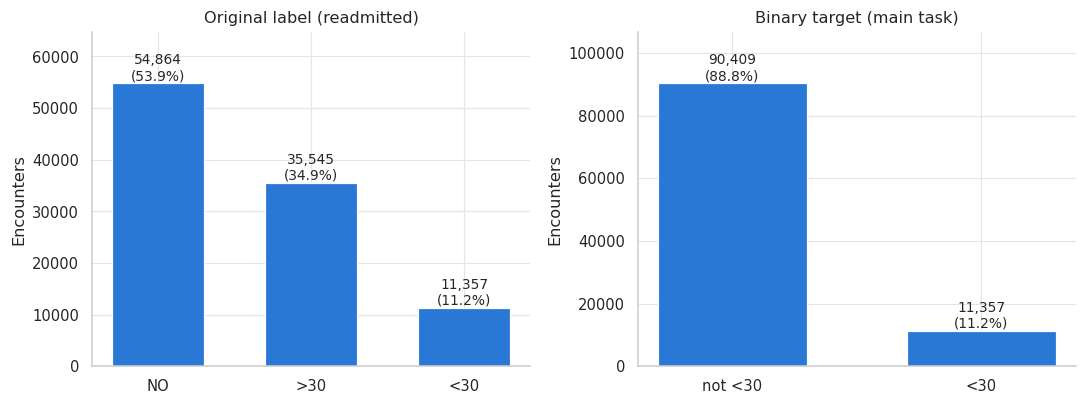

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
plotting.class_distribution(df_raw["readmitted"], "Original label (readmitted)", axes[0])
plotting.class_distribution((df_raw["readmitted"] == "<30").map({True: "<30", False: "not <30"}),
                            "Binary target (main task)", axes[1])
fig.tight_layout(); plotting.save(fig, "fig01_target_distribution_raw"); plt.show()

> **What to look for:** the share of `<30` (about 11 %), i.e. the class imbalance that motivates PR-AUC as the main metric and the imbalance experiments in Section 7.

### 3.2 Missing values
Step 1 of preprocessing: the file encodes missing values as `"?"`, so these are replaced with NaN and the percentage of missing values is reported per column.

'Unknown/Invalid' gender rows: 3
saved figures/fig02_missingness.png


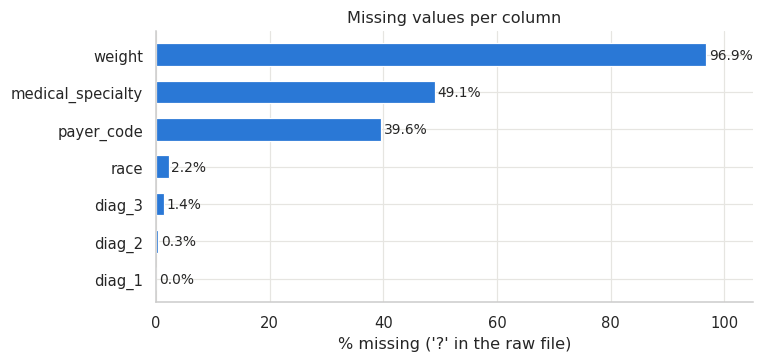

,n_missing,pct_missing
weight,98569,96.86
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


In [6]:
df_raw = data.replace_question_marks(df_raw)
missing = data.missingness_report(df_raw)
missing.to_csv(config.RESULTS_DIR / "missingness_per_column.csv")
print("'Unknown/Invalid' gender rows:", (df_raw["gender"] == "Unknown/Invalid").sum())
fig, ax = plt.subplots(figsize=(7, 3.2))
plotting.missingness_bar(missing, ax); plotting.save(fig, "fig02_missingness"); plt.show()
missing

> **What to look for:** `weight` is almost entirely missing (~97 %); `medical_specialty` (~49 %) and `payer_code` (~40 %) are missing for a large share; `race` and the diagnosis codes have little missingness.

### 3.3 Repeated patients
`patient_nbr` identifies a patient, and many patients have several encounters. If encounters of the same patient end up in both training and test data, the model can partly memorise the patient, which inflates test scores (patient leakage, handled in Section 4.4).

Encounters: 101,766 | patients: 71,518 | patients with >1 encounter: 23.5%
saved figures/fig03_encounters_per_patient.png


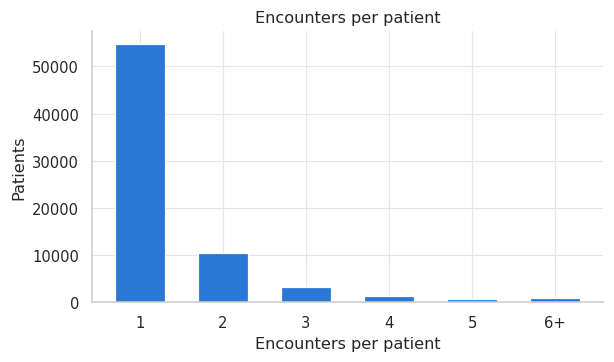

In [7]:
enc_per_patient = df_raw.groupby("patient_nbr").size()
print(f"Encounters: {len(df_raw):,} | patients: {enc_per_patient.size:,} | "
      f"patients with >1 encounter: {(enc_per_patient > 1).mean():.1%}")
counts = enc_per_patient.clip(upper=6).value_counts().sort_index()
counts.index = [str(i) if i < 6 else "6+" for i in counts.index]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(counts.index, counts.values, color=plotting.PALETTE[0], width=0.6)
ax.set_xlabel("Encounters per patient"); ax.set_ylabel("Patients"); ax.set_title("Encounters per patient")
plotting.save(fig, "fig03_encounters_per_patient"); plt.show()

## 4. Preprocessing

### 4.1 Cleaning decisions
| Step | Decision | Reason |
|---|---|---|
| 1 | `"?"` → NaN (done above) | make missingness explicit |
| 2 | drop `weight` | ~97 % missing; imputing it would invent data |
| 2 | `payer_code`, `medical_specialty`, `race` NaN → `"Missing"` | missingness itself may carry information (e.g. no specialty recorded), so it is kept as its own category instead of being imputed |
| 2 | `A1Cresult`, `max_glu_serum` `"None"` → `"Not measured"` | whether a test was ordered is informative (Strack et al. studied exactly this for HbA1c) |
| – | drop 3 rows with gender `"Unknown/Invalid"` | too few to form a category |
| 3 | drop discharge IDs 11, 13, 14, 19, 20, 21 | the patient died or went to hospice, so readmission is impossible; keeping them adds label noise |

In [8]:
cleaning_log = []
df_clean = data.clean(df_raw, cleaning_log)
print(f"Prevalence of <30 after cleaning (all encounters): {df_clean[config.TARGET].mean():.3%}")

Prevalence of <30 after cleaning (all encounters): 11.389%


### 4.2 Patient leakage: two options
* **(a) First encounter per patient** (as in Strack et al., 2014): every row is a different patient, so rows are independent and any ordinary stratified split is leakage-free. The cost is fewer rows.
* **(b) All encounters, split by patient** (`StratifiedGroupKFold` / grouped train-val-test split): keeps more data, but rows of the same patient are correlated and every CV and split must be grouped.

**Main pipeline: option (a).** It is the cleaner design: rows are independent, it matches the reference paper so results are comparable, and the standard `StratifiedKFold` can be used everywhere. Option (b) is run as a separate experiment in Section 7.7, which also shows how much a naive (non-grouped) split inflates the scores.

`encounter_id` is used as the time order because the dataset has no admission dates.

In [9]:
df_a = data.first_encounter_per_patient(df_clean)
cleaning_log.append(("keep first encounter per patient (option a)", len(df_a)))
log_df = pd.DataFrame(cleaning_log, columns=["step", "rows_remaining"])
log_df.to_csv(config.RESULTS_DIR / "data_cleaning_log.csv", index=False)
print(f"Option (a): {len(df_a):,} rows, prevalence {df_a[config.TARGET].mean():.3%}")
print(f"Option (b): {len(df_clean):,} rows, {df_clean.patient_nbr.nunique():,} patients, "
      f"prevalence {df_clean[config.TARGET].mean():.3%}")
log_df

Option (a): 69,987 rows, prevalence 8.980%
Option (b): 99,340 rows, 69,987 patients, prevalence 11.389%


,step,rows_remaining
0,raw,101766
1,drop gender Unknown/Invalid,101763
2,drop expired / hospice discharges,99340
3,keep first encounter per patient (option a),69987


> **What to look for:** the row count after each step, and that the `<30` rate is lower for first encounters than for all encounters (patients with many admissions are the ones most often readmitted).

## 5. Feature engineering

All engineered features below are computed **row by row** (from one encounter's own values), so they can be created before the split without leaking information. Anything learned from data (rare-category collapsing, scaling, encoding) is fitted later on the training split only.

| Feature | Definition | Justification |
|---|---|---|
| `diag_1/2/3_group` | ICD-9 codes → 9 clinical groups (circulatory 390–459, 785; respiratory 460–519, 786; digestive 520–579, 787; diabetes 250.xx; injury 800–999; musculoskeletal 710–739; genitourinary 580–629, 788; neoplasms 140–239; other) | ~700 raw codes per column are too sparse to learn from; the grouping follows Strack et al. (2014) and keeps clinical meaning |
| `total_prior_visits` | outpatient + emergency + inpatient visits in the preceding year | overall healthcare use is a known readmission risk factor |
| `n_med_changes` | number of the 23 drugs whose dose went Up or Down | dose changes signal unstable glycaemic control |
| `n_diabetes_drugs` | number of the 23 drugs prescribed | treatment complexity |
| `age_mid` | `[70-80)` → 75 | keeps the natural order of age brackets, one numeric column instead of 10 dummies |
| `admission_type`, `discharge_disposition`, `admission_source` | readable labels from `IDS_mapping.csv`; NULL / Not Mapped / Not Available merged into `Unknown` | interpretable categories; these three codes all mean "not recorded" |
| rare-level collapsing | levels of `medical_specialty`, `admission_source`, `discharge_disposition` below a frequency threshold → `Other` (threshold tuned in the model search) | avoids dozens of near-empty one-hot columns that add variance |
| `A1Cresult`, `max_glu_serum` | categorical with a `Not measured` level | the decision to test is informative |

`prior_inpatient_bin` (0 / 1 / 2 / 3+) is created only for the subgroup error analysis.

In [10]:
df_a = features.add_engineered_features(df_a, id_maps)
df_all = features.add_engineered_features(df_clean, id_maps)      # used only by the option (b) experiment

if FAST_MODE:   # stratified subsample for quick checks
    from sklearn.model_selection import train_test_split
    df_a, _ = train_test_split(df_a, train_size=FAST_SAMPLE_SIZE, stratify=df_a[config.TARGET],
                               random_state=SEED)
    df_a = df_a.reset_index(drop=True)
    print(f"FAST_MODE: using {len(df_a):,} rows")

df_a[["diag_1", "diag_1_group", "total_prior_visits", "n_med_changes", "n_diabetes_drugs",
      "age", "age_mid", "admission_source", "discharge_disposition"]].head()

,diag_1,diag_1_group,total_prior_visits,n_med_changes,n_diabetes_drugs,age,age_mid,admission_source,discharge_disposition
0,398,Circulatory,0,0,2,[80-90),85.0,Transfer from a hospital,Discharged to home
1,434,Circulatory,0,0,2,[90-100),95.0,Transfer from a hospital,Discharged/transferred to SNF
2,197,Neoplasms,0,0,2,[40-50),45.0,Emergency Room,Discharged to home
3,250.7,Diabetes,0,0,1,[40-50),45.0,Emergency Room,Discharged to home
4,414,Circulatory,0,0,1,[50-60),55.0,Clinic Referral,Discharged to home


### 5.1 Train / validation / test split (70 / 15 / 15)
Stratified on the binary target so all three splits have the same `<30` rate. Because option (a) has one row per patient, no patient can appear in two splits. The validation set is used for model selection, threshold choice and early stopping; **the test set is not used until Section 9**.

In [11]:
y_full = df_a[config.TARGET].to_numpy()
train_idx, val_idx, test_idx = data.stratified_split(y_full, val_size=0.15, test_size=0.15, seed=SEED)
df_train = df_a.iloc[train_idx].reset_index(drop=True)
df_val = df_a.iloc[val_idx].reset_index(drop=True)
df_test = df_a.iloc[test_idx].reset_index(drop=True)      # do not touch until Section 9

assert not set(df_train.patient_nbr) & set(df_test.patient_nbr)
assert not set(df_train.patient_nbr) & set(df_val.patient_nbr)
split_df = data.split_summary(y_full, {"train": train_idx, "validation": val_idx, "test": test_idx})
split_df.to_csv(config.RESULTS_DIR / "split_summary.csv", index=False)
split_df

,split,n,n_positive,pct_positive
0,train,48990,4399,8.98
1,validation,10498,943,8.98
2,test,10499,943,8.98


### 5.2 Training-set EDA
Relationships with the target are explored on the **training split only**, so that no modelling decision is influenced by the test data.

saved figures/fig04_numeric_features_vs_target_train.png


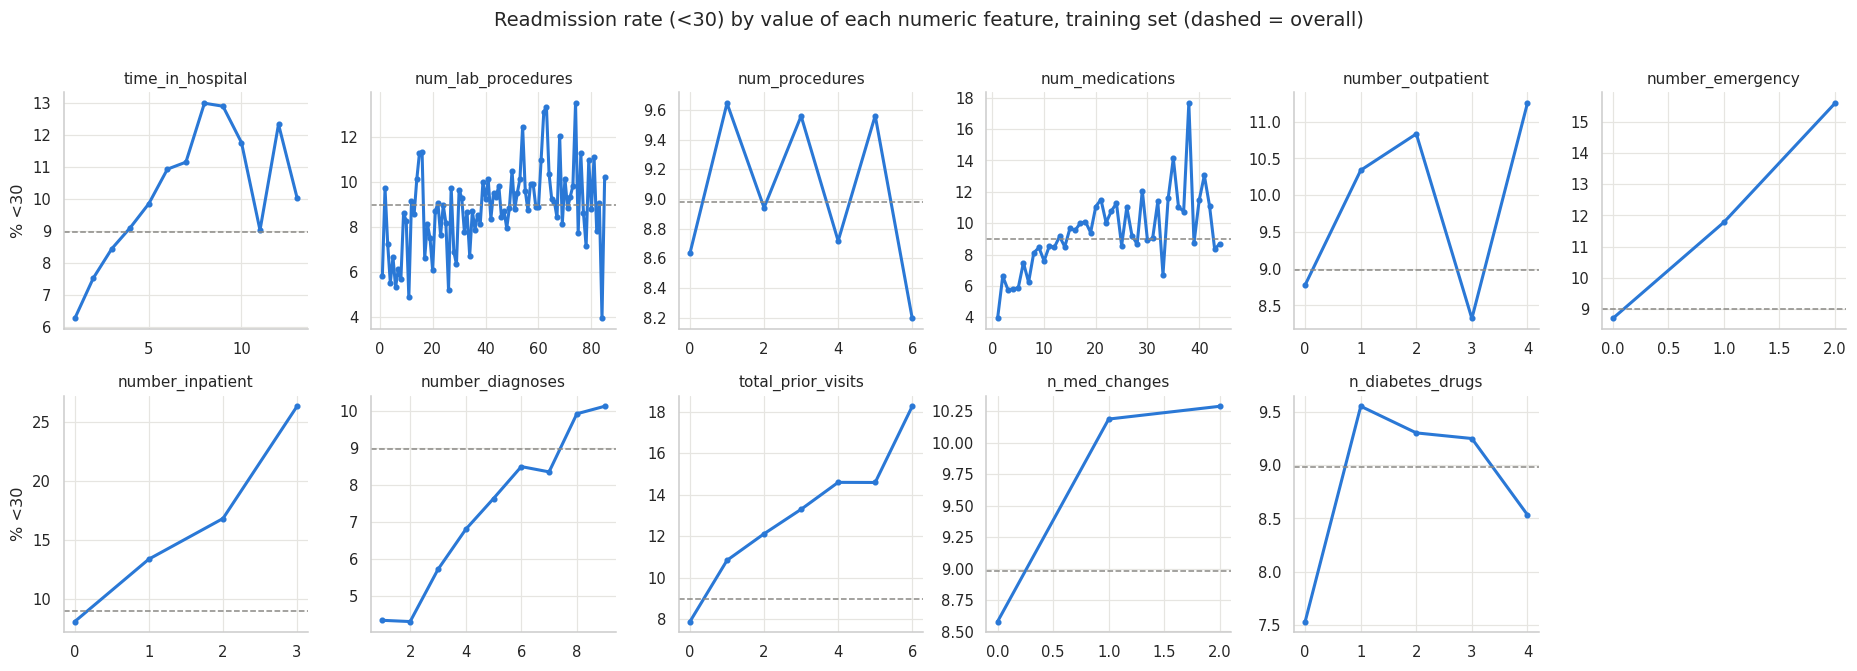

In [12]:
num_cols = config.RAW_NUMERIC_COLS + ["total_prior_visits", "n_med_changes", "n_diabetes_drugs"]
fig, axes = plt.subplots(2, 6, figsize=(17, 6))
for ax, c in zip(axes.ravel(), num_cols):
    rates = df_train.groupby(df_train[c].clip(upper=df_train[c].quantile(0.99)))[config.TARGET].agg(["mean", "size"])
    rates = rates[rates["size"] >= 30]
    ax.plot(rates.index, 100 * rates["mean"], marker="o", ms=3, color=plotting.PALETTE[0])
    ax.axhline(100 * df_train[config.TARGET].mean(), color=plotting.NEUTRAL, ls="--", lw=1)
    ax.set_title(c, fontsize=10); ax.set_ylabel("% <30" if ax in axes[:, 0] else "")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
fig.suptitle("Readmission rate (<30) by value of each numeric feature, training set (dashed = overall)", y=1.01)
fig.tight_layout(); plotting.save(fig, "fig04_numeric_features_vs_target_train"); plt.show()

> **What to look for:** which numeric features show a clear trend in the readmission rate (prior inpatient visits and total prior visits are typically the strongest) and which are flat.

saved figures/fig05_categorical_features_vs_target_train.png


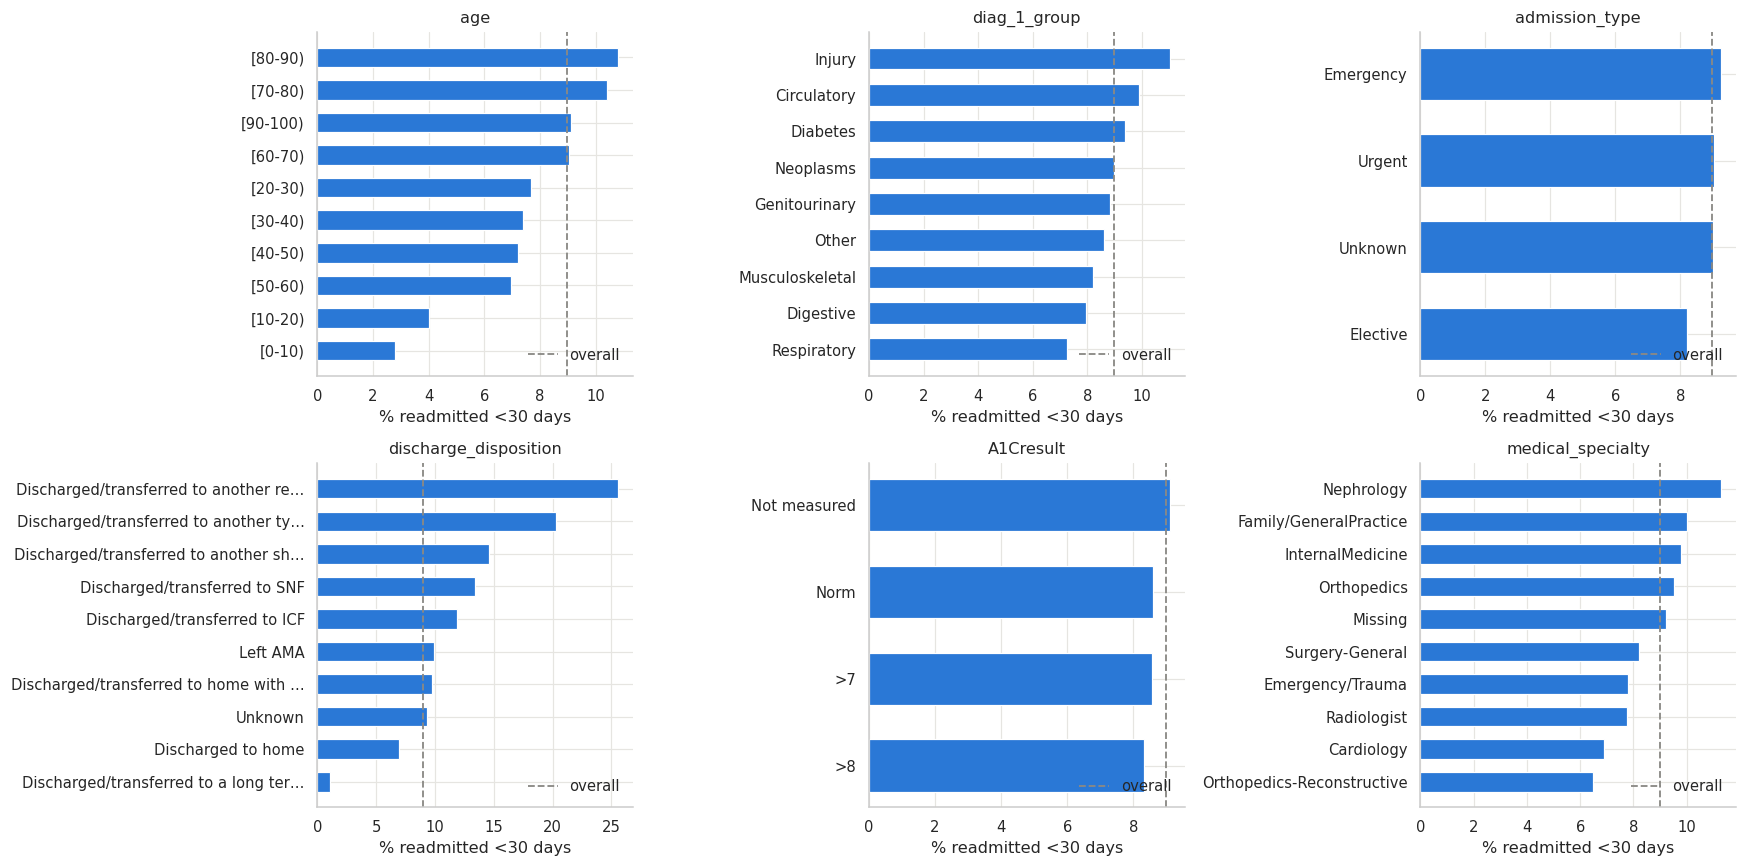

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ["age", "diag_1_group", "admission_type", "discharge_disposition",
                                "A1Cresult", "medical_specialty"]):
    plotting.rate_by_category(df_train, c, config.TARGET, ax=ax, top=10)
fig.tight_layout(); plotting.save(fig, "fig05_categorical_features_vs_target_train"); plt.show()

> **What to look for:** categories with readmission rates far from the overall rate (dashed line), e.g. discharge to another facility vs. home, or the age gradient.

### 5.3 Drop identifiers and near-constant columns
`encounter_id` and `patient_nbr` are identifiers, not patient characteristics, and are never given to the models. Drug columns where a single value covers ≥ 99.9 % of **training** rows (e.g. `examide` and `citoglipton`, which are constant) carry no usable signal and are dropped. Their information is still partly kept in `n_diabetes_drugs` and `n_med_changes`, which were computed from all 23 drugs.

In [14]:
dropped_cols = features.near_constant_columns(df_train, config.DRUG_COLS, NEAR_CONSTANT_THRESHOLD)
kept_drugs = [c for c in config.DRUG_COLS if c not in dropped_cols]
print("Dropped near-constant columns:", dropped_cols)
print("Numeric columns with a single value:", [c for c in config.RAW_NUMERIC_COLS if df_train[c].nunique() < 2])

cols = features.get_feature_columns("engineered", kept_drugs)        # main feature set
cols_base = features.get_feature_columns("baseline", kept_drugs)     # ablation: no engineered features
print(f"Engineered set: {len(cols['numeric'])} numeric + {len(cols['categorical'])} categorical")
print(f"Baseline set:   {len(cols_base['numeric'])} numeric + {len(cols_base['categorical'])} categorical")

X_train, y_train = features.as_model_frame(df_train, cols), df_train[config.TARGET].to_numpy()
X_val, y_val = features.as_model_frame(df_val, cols), df_val[config.TARGET].to_numpy()
Xb_train = features.as_model_frame(df_train, cols_base)

Dropped near-constant columns: ['chlorpropamide', 'acetohexamide', 'tolbutamide', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
Numeric columns with a single value: []
Engineered set: 12 numeric + 25 categorical
Baseline set:   8 numeric + 26 categorical


## 6. Preprocessing pipelines
All learned preprocessing lives inside scikit-learn / imbalanced-learn Pipelines, so in cross-validation it is re-fitted on the training folds only:

```
prep     ColumnTransformer: numeric → median impute + StandardScaler
                            rare-collapse columns → "Missing" impute + RareCategoryCollapser(min_freq)
                            other categoricals → "Missing" impute
sampler  passthrough | RandomUnderSampler | SMOTENC     (only active during fit)
encode   OneHotEncoder(handle_unknown="ignore") on categoricals
clf      estimator
```
SMOTE-NC must see the categorical columns *before* one-hot encoding, which is why encoding is a separate step after the sampler. The cell below fits the preprocessing part on the training set to show its output.

In [15]:
demo_prep = pipelines.build_dense_preprocessor(cols, rare_min_freq=0.01).fit(X_train)
Xt = demo_prep.transform(X_train)
print("Encoded training matrix:", Xt.shape)
collapse = demo_prep.named_steps["prep"].named_transformers_["rare"].named_steps["collapse"]
pd.DataFrame({c: {"levels_before": X_train[c].nunique(), "levels_kept": len(collapse.keep_[c])}
              for c in cols["rare"]}).T

Encoded training matrix: (48990, 155)


,levels_before,levels_kept
medical_specialty,70,10
admission_source,13,6
discharge_disposition,20,7


> **What to look for:** the final number of encoded columns and how many levels of the three high-cardinality columns survive the 1 % threshold (the rest become `Other`).

## 7. Traditional machine learning

Cross-validation uses `StratifiedKFold` on the training split (rows are independent under option a). The main metric is **average precision (PR-AUC)**, which focuses on the minority class and, unlike ROC-AUC, is sensitive to how many false positives come with each true positive; ROC-AUC is logged as a secondary metric. A dummy classifier gives the chance-level reference: its PR-AUC equals the prevalence.

In [16]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate, learning_curve
from sklearn.base import clone

cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
tune_cv = StratifiedKFold(TUNE_CV_FOLDS, shuffle=True, random_state=SEED)

### 7.1 Class-imbalance strategies
Four strategies are compared with untuned Logistic Regression and LightGBM: no handling, `class_weight="balanced"`, random undersampling and SMOTE-NC (the SMOTE variant for mixed numeric/categorical data). Resampling sits inside the imblearn Pipeline, so it is applied only to the training folds and the validation folds keep the true class distribution. The strategy with the best mean CV PR-AUC across both models is used for tuning.

LogReg       none          PR-AUC=0.1627 ROC-AUC=0.6462 (10.0s)
LogReg       class_weight  PR-AUC=0.1617 ROC-AUC=0.6482 (10.4s)
LogReg       undersample   PR-AUC=0.1577 ROC-AUC=0.6439 (2.6s)
LogReg       smote_nc      PR-AUC=0.1117 ROC-AUC=0.5543 (78.6s)
LightGBM     none          PR-AUC=0.1814 ROC-AUC=0.6586 (12.9s)
LightGBM     class_weight  PR-AUC=0.1764 ROC-AUC=0.6551 (12.2s)
LightGBM     undersample   PR-AUC=0.1618 ROC-AUC=0.6480 (5.5s)
LightGBM     smote_nc      PR-AUC=0.1535 ROC-AUC=0.6323 (85.6s)
Strategy used for tuning: none
saved figures/fig06_imbalance_strategies_cv.png


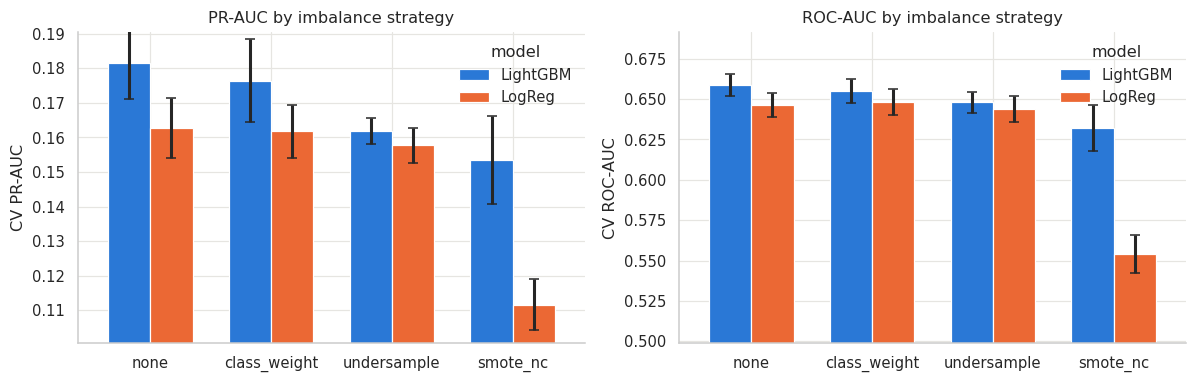

,model,strategy,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,seconds
0,LogReg,none,0.1627,0.0086,0.6462,0.0074,10.0
1,LogReg,class_weight,0.1617,0.0076,0.6482,0.0080,10.4
2,LogReg,undersample,0.1577,0.0050,0.6439,0.0078,2.6
3,LogReg,smote_nc,0.1117,0.0073,0.5543,0.0118,78.6
4,LightGBM,none,0.1814,0.0102,0.6586,0.0069,12.9
5,LightGBM,class_weight,0.1764,0.0121,0.6551,0.0076,12.2
6,LightGBM,undersample,0.1618,0.0037,0.6480,0.0064,5.5
7,LightGBM,smote_nc,0.1535,0.0127,0.6323,0.0143,85.6


In [17]:
imb_df = ml_models.compare_imbalance_strategies(["LogReg", "LightGBM"], X_train, y_train, cols, cv,
                                                pipelines.IMBALANCE_STRATEGIES, n_jobs=N_JOBS, seed=SEED)
imb_df.to_csv(config.RESULTS_DIR / "imbalance_strategies_cv.csv", index=False)

IMBALANCE_STRATEGY = IMBALANCE_OVERRIDE or imb_df.groupby("strategy")["cv_pr_auc_mean"].mean().idxmax()
print("Strategy used for tuning:", IMBALANCE_STRATEGY)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, m, lab in zip(axes, ["cv_pr_auc", "cv_roc_auc"], ["PR-AUC", "ROC-AUC"]):
    piv = imb_df.pivot(index="strategy", columns="model", values=f"{m}_mean").loc[pipelines.IMBALANCE_STRATEGIES]
    err = imb_df.pivot(index="strategy", columns="model", values=f"{m}_std").loc[pipelines.IMBALANCE_STRATEGIES]
    piv.plot.bar(yerr=err, ax=ax, rot=0, width=0.7, capsize=3)
    ax.set_ylim(piv.min().min() * 0.9, piv.max().max() * 1.05); ax.set_ylabel(f"CV {lab}"); ax.set_xlabel("")
    ax.set_title(f"{lab} by imbalance strategy")
fig.tight_layout(); plotting.save(fig, "fig06_imbalance_strategies_cv"); plt.show()
imb_df.round(4)

> **What to look for:** whether resampling changes the threshold-free metrics at all. PR-AUC and ROC-AUC depend on the ranking of predictions, which reweighting barely changes; resampling mostly shifts predicted probabilities (see the calibration plot later). Also compare the run time column, since SMOTE-NC is the slowest.

### 7.2 Feature-engineering ablation
The same two models are cross-validated on the **baseline** set (original columns only: raw ICD-9 codes, raw ID codes, age bracket as a category) and the **engineered** set. For the baseline set, one-hot encoding keeps only levels seen at least `BASELINE_OHE_MIN_FREQ` times; without this, raw ICD-9 codes would create over a thousand mostly empty columns.

saved figures/fig07_feature_ablation_cv.png


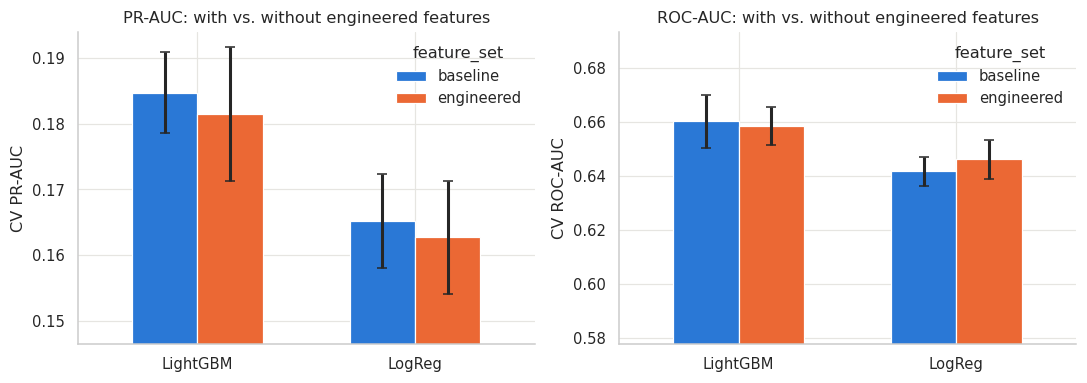

,model,feature_set,n_encoded_columns,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std
0,LogReg,baseline,556,0.1652,0.0072,0.6418,0.0053
1,LogReg,engineered,155,0.1627,0.0086,0.6462,0.0074
2,LightGBM,baseline,556,0.1847,0.0061,0.6604,0.0098
3,LightGBM,engineered,155,0.1814,0.0102,0.6586,0.0069


In [18]:
abl_rows = []
for name in ["LogReg", "LightGBM"]:
    for set_name, c, X_, ohe_min in [("baseline", cols_base, Xb_train, BASELINE_OHE_MIN_FREQ),
                                     ("engineered", cols, X_train, None)]:
        pipe = pipelines.build_model_pipeline(ml_models.make_estimator(name, IMBALANCE_STRATEGY, SEED), c,
                                              IMBALANCE_STRATEGY, onehot_min_frequency=ohe_min, seed=SEED)
        res = cross_validate(pipe, X_, y_train, cv=cv, scoring=ml_models.SCORING, n_jobs=N_JOBS)
        n_cols = clone(pipe)[:-1].fit(X_, y_train).transform(X_.iloc[:5]).shape[1]
        abl_rows.append({"model": name, "feature_set": set_name, "n_encoded_columns": n_cols,
                         "cv_pr_auc_mean": res["test_pr_auc"].mean(), "cv_pr_auc_std": res["test_pr_auc"].std(),
                         "cv_roc_auc_mean": res["test_roc_auc"].mean(), "cv_roc_auc_std": res["test_roc_auc"].std()})
abl_df = pd.DataFrame(abl_rows)
abl_df.to_csv(config.RESULTS_DIR / "feature_ablation_cv.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, m, lab in zip(axes, ["cv_pr_auc", "cv_roc_auc"], ["PR-AUC", "ROC-AUC"]):
    piv = abl_df.pivot(index="model", columns="feature_set", values=f"{m}_mean")[["baseline", "engineered"]]
    err = abl_df.pivot(index="model", columns="feature_set", values=f"{m}_std")[["baseline", "engineered"]]
    piv.plot.bar(yerr=err, ax=ax, rot=0, width=0.6, capsize=3)
    ax.set_ylim(piv.min().min() * 0.9, piv.max().max() * 1.05); ax.set_ylabel(f"CV {lab}"); ax.set_xlabel("")
    ax.set_title(f"{lab}: with vs. without engineered features")
fig.tight_layout(); plotting.save(fig, "fig07_feature_ablation_cv"); plt.show()
abl_df.round(4)

> **What to look for:** the size of the difference relative to the fold-to-fold standard deviation, and the difference in the number of encoded columns (model complexity) between the two sets.

### 7.3 Hyperparameter tuning
`RandomizedSearchCV` with `StratifiedKFold`, refitting on PR-AUC and logging ROC-AUC. Every model's search also tunes the rare-category threshold (`prep__rare__collapse__min_freq`). Models:

* **Dummy** (predicts the prior): chance-level reference.
* **Logistic Regression**: L1 vs. L2 penalty and `C`. A linear, well-calibrated baseline.
* **Random Forest**: bagged trees; depth, leaf size, feature and row sub-sampling.
* **HistGradientBoosting**: scikit-learn's histogram gradient boosting.
* **LightGBM**: gradient boosting with leaf-wise growth, row/column sub-sampling and L2 regularisation.
* **Linear SVM**: `LinearSVC` wrapped in `CalibratedClassifierCV` (sigmoid), because SVMs do not output probabilities and a kernel SVM is too slow at this size.

Every configuration and its CV scores are written to `results/ml_cv_results_all.csv`.

In [19]:
ML_MODELS = ["Dummy", "LogReg", "RandomForest", "HistGB", "LightGBM", "LinearSVM"]
searches, cv_tables = {}, []
t_start = time.time()
for name in ML_MODELS:
    s, tbl = ml_models.tune_model(name, X_train, y_train, cols, tune_cv, IMBALANCE_STRATEGY,
                                  N_ITER.get(name, 0), n_jobs=N_JOBS, seed=SEED)
    searches[name] = s
    cv_tables.append(tbl)
print(f"Total tuning time: {(time.time() - t_start) / 60:.1f} min")

ml_cv_results = pd.concat(cv_tables, ignore_index=True)
ml_cv_results.to_csv(config.RESULTS_DIR / "ml_cv_results_all.csv", index=False)
final_ml = {n: getattr(s, "best_estimator_", s) for n, s in searches.items()}
best_params = {n: getattr(s, "best_params_", {}) for n, s in searches.items()}

best_cv = (ml_cv_results.sort_values("mean_test_pr_auc", ascending=False).groupby("model").head(1)
           .set_index("model").loc[ML_MODELS])
best_cv.to_csv(config.RESULTS_DIR / "ml_cv_best_per_model.csv")
best_cv[["mean_test_pr_auc", "std_test_pr_auc", "mean_test_roc_auc", "std_test_roc_auc", "mean_fit_time", "params"]].round(4)

Dummy: CV PR-AUC=0.0898
LogReg: best CV PR-AUC=0.1613 (12 configs, 61s)
  best params: {'clf__C': np.float64(0.8471801418819978), 'clf__l1_ratio': 0.0, 'prep__rare__collapse__min_freq': 0.005}
RandomForest: best CV PR-AUC=0.1694 (8 configs, 187s)
  best params: {'prep__rare__collapse__min_freq': 0.005, 'clf__n_estimators': 200, 'clf__min_samples_leaf': 20, 'clf__max_samples': 0.5, 'clf__max_features': 'sqrt', 'clf__max_depth': 20}
HistGB: best CV PR-AUC=0.1709 (12 configs, 93s)
  best params: {'clf__l2_regularization': np.float64(5.872283616443723), 'clf__learning_rate': np.float64(0.07316749954053857), 'clf__max_iter': 400, 'clf__max_leaf_nodes': 15, 'clf__min_samples_leaf': 50, 'prep__rare__collapse__min_freq': 0.005}
LightGBM: best CV PR-AUC=0.1769 (15 configs, 143s)
  best params: {'clf__colsample_bytree': np.float64(0.5870266456536466), 'clf__learning_rate': np.float64(0.03311829888072381), 'clf__min_child_samples': 50, 'clf__n_estimators': 400, 'clf__num_leaves': 15, 'clf__reg_la

,mean_test_pr_auc,std_test_pr_auc,mean_test_roc_auc,std_test_roc_auc,mean_fit_time,params
model,,,,,,
Dummy,0.0898,0.0000,0.5000,0.0000,0.5375,{}
LogReg,0.1613,0.0081,0.6421,0.0077,1.7555,"{'clf__C': 0.8471801418819978, 'clf__l1_ratio'..."
RandomForest,0.1694,0.0107,0.6565,0.0094,7.4687,"{'prep__rare__collapse__min_freq': 0.005, 'clf..."
HistGB,0.1709,0.0072,0.6537,0.0084,4.0991,"{'clf__l2_regularization': 5.872283616443723, ..."
LightGBM,0.1769,0.0085,0.6588,0.0073,3.2569,"{'clf__colsample_bytree': 0.5870266456536466, ..."
LinearSVM,0.1634,0.0085,0.6461,0.0069,1.7247,"{'clf__estimator__C': 0.003148911647956862, 'p..."


> **What to look for:** the gap between each model and the Dummy baseline, and the gaps between models relative to the CV standard deviations.

saved figures/fig08_ml_tuning_all_configs_cv.png


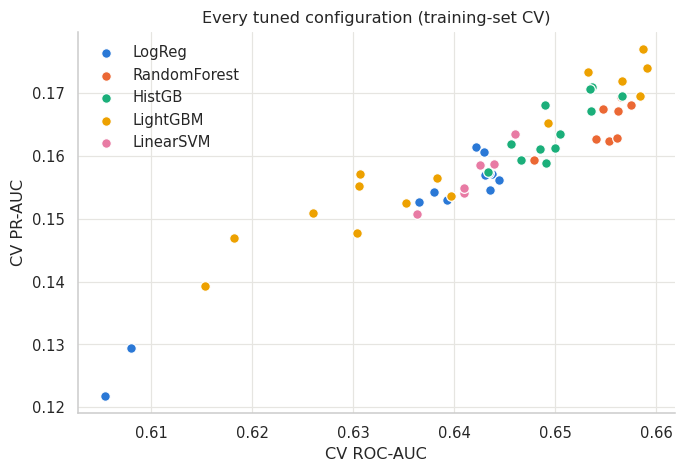

In [20]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, name in enumerate([m for m in ML_MODELS if m != "Dummy"]):
    d = ml_cv_results[ml_cv_results.model == name]
    ax.scatter(d["mean_test_roc_auc"], d["mean_test_pr_auc"], s=40, label=name,
               color=plotting.PALETTE[i], edgecolor="white", linewidth=0.8)
ax.set_xlabel("CV ROC-AUC"); ax.set_ylabel("CV PR-AUC")
ax.set_title("Every tuned configuration (training-set CV)"); ax.legend()
plotting.save(fig, "fig08_ml_tuning_all_configs_cv"); plt.show()

### 7.4 Validation-set scores and decision thresholds
The tuned models predict the validation set. Two thresholds are chosen **on validation data**, never the default 0.5: the threshold that maximises F1, and the highest threshold that still reaches recall ≥ 0.70 (a screening-style operating point). These thresholds are then fixed and reused on the test set.

In [21]:
val_proba = {n: m.predict_proba(X_val)[:, 1] for n, m in final_ml.items()}
thresholds = {n: evaluation.choose_thresholds(y_val, p, TARGET_RECALL) for n, p in val_proba.items()}

val_rows = []
for n, p in val_proba.items():
    met = evaluation.binary_metrics(y_val, p, thresholds[n]["f1_threshold"])
    val_rows.append({"model": n, "family": "ML", "val_pr_auc": met["pr_auc"], "val_roc_auc": met["roc_auc"],
                     "val_f1": met["f1"], **{k: thresholds[n][k] for k in ["f1_threshold", "recall_threshold"]}})
val_ml = pd.DataFrame(val_rows).sort_values("val_pr_auc", ascending=False)
best_ml_name = val_ml[val_ml.model != "Dummy"].iloc[0]["model"]
print("Best traditional model on validation PR-AUC:", best_ml_name)
val_ml.round(4)

Best traditional model on validation PR-AUC: LightGBM


,model,family,val_pr_auc,val_roc_auc,val_f1,f1_threshold,recall_threshold
4,LightGBM,ML,0.1834,0.6419,0.2504,0.1330,0.0712
2,RandomForest,ML,0.1796,0.6413,0.2446,0.1220,0.0804
3,HistGB,ML,0.1775,0.6377,0.2468,0.1281,0.0721
5,LinearSVM,ML,0.1693,0.6328,0.2391,0.1100,0.0713
1,LogReg,ML,0.1673,0.6319,0.2332,0.1379,0.0704
0,Dummy,ML,0.0898,0.5000,0.1648,0.0898,0.0898


saved figures/fig09_threshold_selection_best_ml_val.png


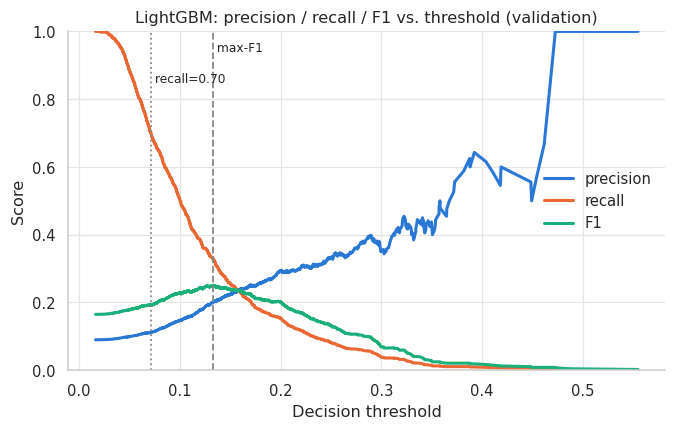

In [22]:
fig, ax = plt.subplots(figsize=(7, 4))
plotting.threshold_curve(y_val, val_proba[best_ml_name], thresholds[best_ml_name],
                         f"{best_ml_name}: precision / recall / F1 vs. threshold (validation)", ax)
plotting.save(fig, "fig09_threshold_selection_best_ml_val"); plt.show()

> **What to look for:** how far the max-F1 threshold is from 0.5 and the precision cost of moving to the recall-0.70 threshold.

### 7.5 Learning curves (bias vs. variance)
scikit-learn `learning_curve` for the two best traditional models: PR-AUC on the training folds vs. the CV folds as the training set grows. A large, persistent gap suggests variance (over-fitting); two low curves that meet suggest bias (the features or model are limiting).

saved figures/fig10_learning_curves_top2_ml.png


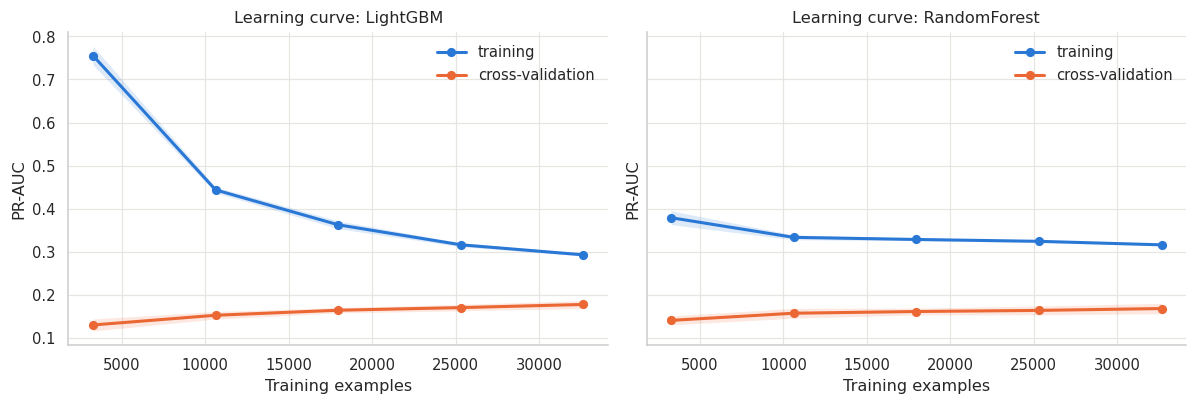

In [23]:
top2_ml = val_ml[val_ml.model != "Dummy"]["model"].head(2).tolist()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
lc_rows = []
for ax, name in zip(axes, top2_ml):
    sizes, tr_sc, va_sc = learning_curve(clone(final_ml[name]), X_train, y_train, cv=tune_cv,
                                         scoring="average_precision", n_jobs=N_JOBS,
                                         train_sizes=np.linspace(0.1, 1.0, 5), shuffle=True, random_state=SEED)
    plotting.learning_curve_plot(sizes, tr_sc, va_sc, f"Learning curve: {name}", ax)
    lc_rows += [{"model": name, "train_size": s, "train_pr_auc": a.mean(), "cv_pr_auc": b.mean()}
                for s, a, b in zip(sizes, tr_sc, va_sc)]
fig.tight_layout(); plotting.save(fig, "fig10_learning_curves_top2_ml"); plt.show()
pd.DataFrame(lc_rows).to_csv(config.RESULTS_DIR / "learning_curves_ml.csv", index=False)

> **What to look for:** the size of the train–CV gap at the largest training size, and whether the CV curve is still rising (more data would help) or flat.

### 7.6 Experiment: patient leakage (option b)
Option (b) keeps every encounter. To leave the test set untouched, this experiment uses only patients from the option (a) **training** split (all of their encounters) and cross-validates the tuned LightGBM pipeline three ways:

1. option (a) – first encounters only, `StratifiedKFold` (the main pipeline);
2. option (b) – all encounters, `StratifiedGroupKFold` by `patient_nbr` (correct for repeated patients);
3. option (b) – all encounters, plain `StratifiedKFold` (the same patient can be in training and validation folds: leaky).

Prevalence differs between (a) and (b), and PR-AUC depends on prevalence, so the table also reports PR-AUC divided by prevalence (lift).
The cell also shows the grouped 70/15/15 split function on all encounters and checks that no patient falls into two splits.

     split     n  n_positive  pct_positive
     train 70958        8082         11.39
validation 14191        1616         11.39
      test 14191        1616         11.39
saved figures/fig11_patient_leakage_experiment.png


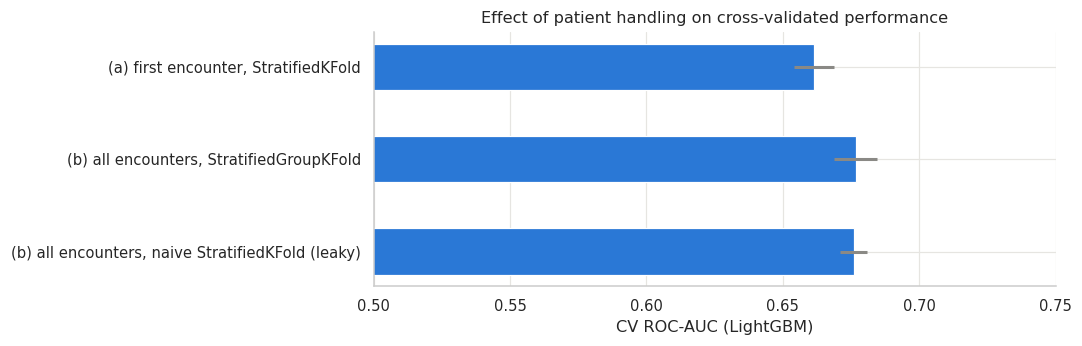

,setup,rows,prevalence,cv_pr_auc_mean,cv_pr_auc_std,cv_roc_auc_mean,cv_roc_auc_std,pr_auc_lift
0,"(a) first encounter, StratifiedKFold",48990,0.0898,0.1813,0.0095,0.6615,0.0072,2.0190
1,"(b) all encounters, StratifiedGroupKFold",69369,0.1142,0.2277,0.0144,0.6767,0.0080,1.9942
2,"(b) all encounters, naive StratifiedKFold (leaky)",69369,0.1142,0.2286,0.0047,0.6760,0.0049,2.0025


In [24]:
train_patients = set(df_train.patient_nbr)
df_b = df_all[df_all.patient_nbr.isin(train_patients)].reset_index(drop=True)
X_b, y_b, g_b = features.as_model_frame(df_b, cols), df_b[config.TARGET].to_numpy(), df_b.patient_nbr.to_numpy()
lgbm_pipe = final_ml["LightGBM"]

leak_rows = []
for label, X_, y_, cv_, groups in [
        ("(a) first encounter, StratifiedKFold", X_train, y_train, cv, None),
        ("(b) all encounters, StratifiedGroupKFold", X_b, y_b,
         StratifiedGroupKFold(CV_FOLDS, shuffle=True, random_state=SEED), g_b),
        ("(b) all encounters, naive StratifiedKFold (leaky)", X_b, y_b, cv, None)]:
    res = cross_validate(clone(lgbm_pipe), X_, y_, groups=groups, cv=cv_, scoring=ml_models.SCORING, n_jobs=N_JOBS)
    leak_rows.append({"setup": label, "rows": len(y_), "prevalence": y_.mean(),
                      "cv_pr_auc_mean": res["test_pr_auc"].mean(), "cv_pr_auc_std": res["test_pr_auc"].std(),
                      "cv_roc_auc_mean": res["test_roc_auc"].mean(), "cv_roc_auc_std": res["test_roc_auc"].std(),
                      "pr_auc_lift": res["test_pr_auc"].mean() / y_.mean()})
leak_df = pd.DataFrame(leak_rows)
leak_df.to_csv(config.RESULTS_DIR / "patient_leakage_experiment_cv.csv", index=False)

# grouped 70/15/15 split on all encounters (option b) - checked for patient overlap
tr_b, va_b, te_b = data.grouped_stratified_split(df_all[config.TARGET], df_all.patient_nbr, seed=SEED)
pid = df_all.patient_nbr.to_numpy()
assert not (set(pid[tr_b]) & set(pid[te_b])) and not (set(pid[tr_b]) & set(pid[va_b]))
grouped_split_df = data.split_summary(df_all[config.TARGET], {"train": tr_b, "validation": va_b, "test": te_b})
grouped_split_df.to_csv(config.RESULTS_DIR / "grouped_split_summary_option_b.csv", index=False)
print(grouped_split_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(leak_df["setup"][::-1], leak_df["cv_roc_auc_mean"][::-1], xerr=leak_df["cv_roc_auc_std"][::-1],
        color=plotting.PALETTE[0], height=0.5, error_kw={"ecolor": plotting.NEUTRAL})
ax.set_xlim(0.5, max(0.75, leak_df["cv_roc_auc_mean"].max() + 0.03)); ax.set_xlabel("CV ROC-AUC (LightGBM)")
ax.set_title("Effect of patient handling on cross-validated performance")
plotting.save(fig, "fig11_patient_leakage_experiment"); plt.show()
leak_df.round(4)

> **What to look for:** the difference between the grouped and the naive split on the same rows (pure leakage effect), and how option (b) grouped compares with option (a).

## 8. Deep learning (TensorFlow / Keras)

### 8.1 Inputs for the networks
Two fitted preprocessors (fitted on the training split only, using the rare-category threshold chosen by the best traditional model):

* **dense**: the same impute → collapse → scale → one-hot pipeline as above, giving one float matrix (Experiments 1–2);
* **embedding**: integer indices for the high-cardinality categoricals (diagnosis groups, specialty, admission type/source, discharge disposition, payer) plus a float block with the numeric and remaining one-hot columns (Experiments 3–4). Index 0 is reserved for categories not seen in training.

In [25]:
best_rare = best_params[best_ml_name].get("prep__rare__collapse__min_freq", 0.01)
print("Rare-category threshold used for DL:", best_rare)

dense_prep = pipelines.build_dense_preprocessor(cols, rare_min_freq=best_rare).fit(X_train)
Xtr_d = dense_prep.transform(X_train).astype("float32")
Xva_d = dense_prep.transform(X_val).astype("float32")

emb_prep = pipelines.EmbeddingPreprocessor(cols, rare_min_freq=best_rare).fit(X_train)
Xtr_e, Xva_e = emb_prep.transform(X_train), emb_prep.transform(X_val)
print("Dense input:", Xtr_d.shape)
print("Embedding inputs:", {k: v.shape for k, v in Xtr_e.items()})
print("Cardinalities (incl. unknown index 0):", emb_prep.cardinalities_)

Rare-category threshold used for DL: 0.01
Dense input: (48990, 155)
Embedding inputs: {'numeric': (48990, 75), 'diag_1_group': (48990,), 'diag_2_group': (48990,), 'diag_3_group': (48990,), 'medical_specialty': (48990,), 'admission_source': (48990,), 'discharge_disposition': (48990,), 'admission_type': (48990,), 'payer_code': (48990,)}
Cardinalities (incl. unknown index 0): {'diag_1_group': 11, 'diag_2_group': 11, 'diag_3_group': 11, 'medical_specialty': 12, 'admission_source': 8, 'discharge_disposition': 9, 'admission_type': 7, 'payer_code': 19}


### 8.2 The `tf.data` input pipeline
Every model is fed through the same pipeline:

```
Dataset.from_tensor_slices((X, y))  ->  .cache()  ->  .shuffle(n, seed)  ->  .batch(B)  ->  .prefetch(AUTOTUNE)
```
`cache` keeps the tensors in memory after the first epoch, `shuffle` (training only, seeded, reshuffled every epoch) uses a buffer the size of the dataset so the shuffle is complete, and `prefetch` prepares the next batch while the current one trains. For the embedding model `X` is a dict whose keys match the named `Input` layers.

In [26]:
def make_sets(X_tr, X_va, batch_size=DL_BATCH_SIZE):
    return (dl_models.make_dataset(X_tr, y_train, batch_size, shuffle=True, seed=SEED),
            dl_models.make_dataset(X_va, y_val, batch_size=2048))

train_ds_d, val_ds_d = make_sets(Xtr_d, Xva_d)
train_ds_e, val_ds_e = make_sets(Xtr_e, Xva_e)
print("Dense element_spec:", train_ds_d.element_spec)
xb, yb = next(iter(train_ds_e))
print("One embedding batch:", {k: tuple(v.shape) for k, v in xb.items()}, "labels", tuple(yb.shape))

Dense element_spec: (TensorSpec(shape=(None, 155), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
One embedding batch: {'numeric': (512, 75), 'diag_1_group': (512,), 'diag_2_group': (512,), 'diag_3_group': (512,), 'medical_specialty': (512,), 'admission_source': (512,), 'discharge_disposition': (512,), 'admission_type': (512,), 'payer_code': (512,)} labels (512, 1)


### 8.3 Training set-up shared by all experiments
* Loss: binary cross-entropy (Experiment 4 adds class weights / focal loss); optimiser Adam.
* Metrics: PR-AUC (`AUC(curve="PR")`), ROC-AUC, precision and recall.
* Callbacks: `EarlyStopping` on validation PR-AUC (best weights restored), `ReduceLROnPlateau` on validation PR-AUC, `ModelCheckpoint` (best epoch saved to `models/checkpoints/`).

The helper below trains one run, saves its loss/AUC curves and stores its validation predictions.

In [27]:
dl_runs = {}

def run_experiment(run_name, model, train_ds, val_ds, X_val_in, fig_name, class_weight=None):
    config.set_global_seed(SEED)
    hist = dl_models.train(model, train_ds, val_ds, run_name, epochs=DL_EPOCHS,
                           class_weight=class_weight, patience=DL_PATIENCE)
    hist.to_csv(config.RESULTS_DIR / f"dl_history_{run_name}.csv")
    fig = plotting.history_plot(hist, f"{run_name}: training vs. validation")
    plotting.save(fig, fig_name); plt.show()
    p = dl_models.predict_proba(model, X_val_in)
    dl_runs[run_name] = {"model": model, "hist": hist, "val_proba": p,
                         "input": "embedding" if isinstance(X_val_in, dict) else "dense"}
    return hist

### 8.4 Experiment 1 – Baseline MLP (Sequential API)
One hidden layer of 64 ReLU units on the dense one-hot + scaled features. No regularisation: this is the reference point for the later experiments.

Model: "exp1_baseline_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         9,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,049 (39.25 KB)

 Trainable params: 10,049 (39.25 KB)

 Non-trainable params: 0 (0.00 B)

exp1_baseline_mlp: 24 epochs, best val PR-AUC=0.1730 (epoch 16), 20s
saved figures/fig12_dl_exp1_baseline_mlp_history.png


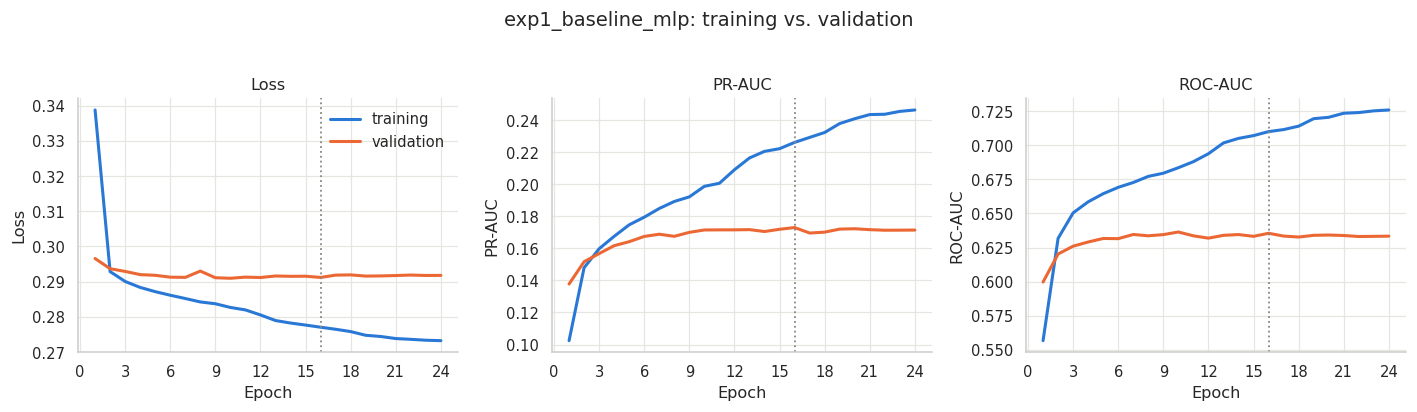

In [28]:
config.set_global_seed(SEED)
m1 = dl_models.compile_model(dl_models.build_baseline_mlp(Xtr_d.shape[1]), learning_rate=1e-3)
m1.summary()
run_experiment("exp1_baseline_mlp", m1, train_ds_d, val_ds_d, Xva_d, "fig12_dl_exp1_baseline_mlp_history");

> **What to look for:** whether validation loss starts rising while training loss keeps falling (over-fitting), and the epoch where validation PR-AUC peaks (dotted line).

### 8.5 Experiment 2 – Deeper MLP with BatchNorm, Dropout and L2 (Functional API)
Three blocks (256 → 128 → 64) of Dense → BatchNormalization → ReLU → Dropout(0.3), with L2 weight decay (1e-4) on every Dense kernel. Regularisation should let a larger network train longer without over-fitting.

Model: "exp2_deep_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ features (InputLayer)           │ (None, 155)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_dense (Dense)            │ (None, 256)            │        39,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn (BatchNormalization)  │ (None, 256)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu (Activation)        │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_drop (Dropout)           │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_dense (Dense)            │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn (BatchNormalization)  │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu (Activation)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_drop (Dropout)           │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_dense (Dense)            │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn (BatchNormalization)  │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu (Activation)        │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_drop (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ readmit_prob (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 82,945 (324.00 KB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 896 (3.50 KB)

exp2_deep_mlp: 20 epochs, best val PR-AUC=0.1711 (epoch 12), 23s
saved figures/fig13_dl_exp2_deep_mlp_history.png


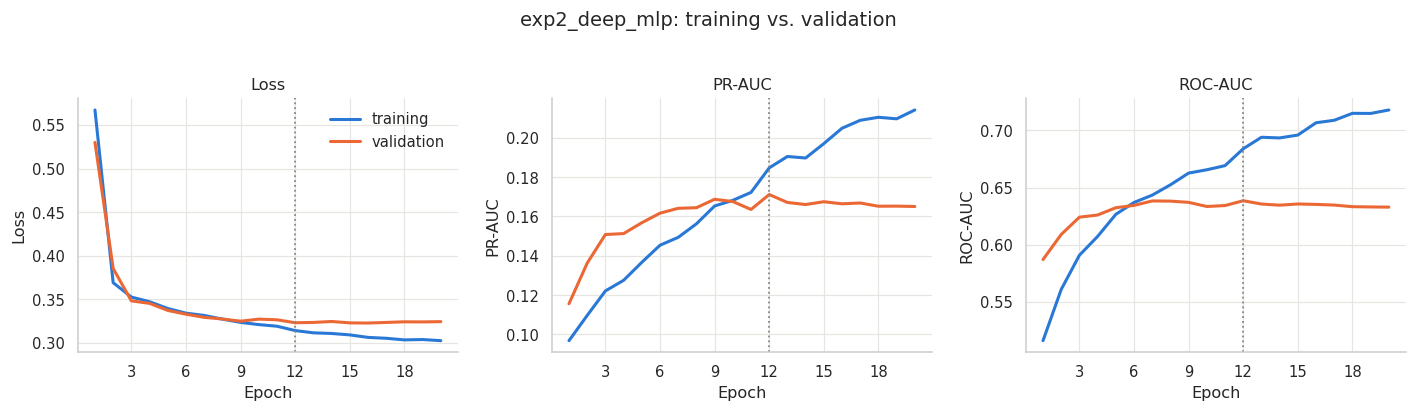

In [29]:
config.set_global_seed(SEED)
m2 = dl_models.compile_model(dl_models.build_deep_mlp(Xtr_d.shape[1], units=(256, 128, 64),
                                                      dropout=0.3, l2=1e-4), learning_rate=1e-3)
m2.summary()
run_experiment("exp2_deep_mlp", m2, train_ds_d, val_ds_d, Xva_d, "fig13_dl_exp2_deep_mlp_history");

### 8.6 Experiment 3 – Learned embeddings for high-cardinality categoricals (Functional API)
Each high-cardinality categorical gets its own `Embedding` layer (size `min(8, ⌈levels/2⌉)`), so the network learns a dense representation where similar categories (e.g. similar discharge destinations) can end up close together, instead of treating every one-hot column as unrelated. The embeddings are concatenated with the numeric block and passed through two regularised Dense blocks.

Model: "exp3_embedding_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ diag_1_group        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ diag_2_group        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ diag_3_group        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ medical_specialty   │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ admission_source    │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ discharge_disposit… │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ admission_type      │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ payer_code          │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_diag_1_group    │ (None, 6)         │         66 │ diag_1_group[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_diag_2_group    │ (None, 6)         │         66 │ diag_2_group[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_diag_3_group    │ (None, 6)         │         66 │ diag_3_group[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_medical_specia… │ (None, 6)         │         72 │ medical_specialt… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_admission_sour… │ (None, 4)         │         32 │ admission_source… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_discharge_disp… │ (None, 5)         │         45 │ discharge_dispos… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_admission_type  │ (None, 4)         │         28 │ admission_type[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_payer_code      │ (None, 8)         │        152 │ payer_code[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 75)        │          0 │ -               

 Total params: 25,104 (98.06 KB)

 Trainable params: 24,720 (96.56 KB)

 Non-trainable params: 384 (1.50 KB)

exp3_embedding_model: 18 epochs, best val PR-AUC=0.1680 (epoch 10), 28s
saved figures/fig14_dl_exp3_embedding_history.png


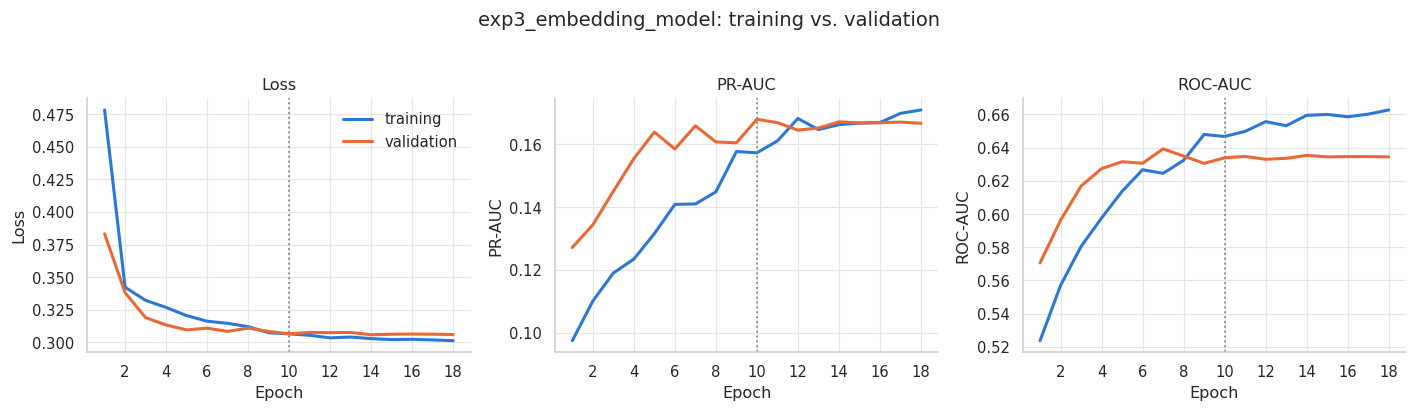

In [30]:
config.set_global_seed(SEED)
m3 = dl_models.compile_model(dl_models.build_embedding_model(emb_prep.cardinalities_, emb_prep.n_numeric_,
                                                             emb_size=8, units=(128, 64), dropout=0.3, l2=1e-4),
                             learning_rate=1e-3)
m3.summary()
run_experiment("exp3_embedding_model", m3, train_ds_e, val_ds_e, Xva_e, "fig14_dl_exp3_embedding_history");

### 8.7 Hyperparameter tuning with KerasTuner (Hyperband)
Hyperband tunes the embedding architecture on the validation set: learning rate, batch size, number of layers, width, dropout, L2 and embedding size. Batch size is tuned by overriding `HyperModel.fit`, so each trial builds its own `tf.data` pipeline. Hyperband trains many configurations for a few epochs and continues only the promising ones, which is much cheaper than a full grid. The objective is validation PR-AUC.

In [31]:
config.set_global_seed(SEED)
hypermodel = dl_models.EmbeddingHyperModel(emb_prep.cardinalities_, emb_prep.n_numeric_, seed=SEED)
tuner = kt.Hyperband(hypermodel, objective=kt.Objective("val_pr_auc", direction="max"),
                     max_epochs=TUNER_MAX_EPOCHS, factor=3, hyperband_iterations=1, seed=SEED,
                     directory=str(config.TUNER_DIR), project_name="embedding_hyperband", overwrite=True)
tuner.search_space_summary()
t0 = time.time()
tuner.search(Xtr_e, y_train, validation_data=(Xva_e, y_val), verbose=0,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=3)])
print(f"Tuning finished in {(time.time() - t0) / 60:.1f} min, {len(tuner.oracle.trials)} trials")
best_hp = tuner.get_best_hyperparameters(1)[0]
tuner_df = dl_models.hp_summary(tuner, n=15)
tuner_df.to_csv(config.RESULTS_DIR / "keras_tuner_top_trials.csv", index=False)
tuner_df.round(4)

Search space summary
Default search space size: 6
n_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units (Choice)
{'default': 64, 'conditions': [], 'values': [64, 128, 256], 'ordered': True}
emb_size (Choice)
{'default': 4, 'conditions': [], 'values': [4, 8, 16], 'ordered': True}
dropout (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
l2 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 1e-05, 0.0001, 0.001], 'ordered': True}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.003, 'step': None, 'sampling': 'log'}
Tuning finished in 6.8 min, 30 trials


,trial_id,val_pr_auc,n_layers,units,emb_size,dropout,l2,learning_rate,batch_size,tuner/epochs,tuner/initial_epoch,tuner/bracket,tuner/round,tuner/trial_id
0,0016,0.1814,3,128,4,0.1,0.0010,0.0016,256,20,7,2,2,0014
1,0017,0.1750,1,64,8,0.4,0.0001,0.0013,512,20,7,2,2,0013
2,0027,0.1733,3,128,4,0.4,0.0010,0.0021,256,20,0,0,0,NaN
3,0014,0.1732,3,128,4,0.1,0.0010,0.0016,256,7,3,2,1,0010
4,0013,0.1683,1,64,8,0.4,0.0001,0.0013,512,7,3,2,1,0007
5,0026,0.1671,1,256,4,0.3,0.0010,0.0003,256,20,0,0,0,NaN
6,0025,0.1671,1,256,8,0.2,0.0010,0.0005,1024,20,7,1,1,0020
7,0024,0.1640,1,128,8,0.0,0.0010,0.0011,1024,20,7,1,1,0021
8,0021,0.1632,1,128,8,0.0,0.0010,0.0011,1024,7,0,1,0,NaN
9,0012,0.1622,2,256,16,0.0,0.0000,0.0006,256,7,3,2,1,0005


> **What to look for:** whether the top trials agree on some settings (e.g. learning rate range or depth); if they vary widely, the model is not sensitive to that hyperparameter.

Model: "tuned_embedding_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ diag_1_group        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ diag_2_group        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ diag_3_group        │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ medical_specialty   │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ admission_source    │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ discharge_disposit… │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ admission_type      │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ payer_code          │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_diag_1_group    │ (None, 4)         │         44 │ diag_1_group[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_diag_2_group    │ (None, 4)         │         44 │ diag_2_group[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_diag_3_group    │ (None, 4)         │         44 │ diag_3_group[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_medical_specia… │ (None, 4)         │         48 │ medical_specialt… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_admission_sour… │ (None, 4)         │         32 │ admission_source… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_discharge_disp… │ (None, 4)         │         36 │ discharge_dispos… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_admission_type  │ (None, 4)         │         28 │ admission_type[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ emb_payer_code      │ (None, 4)         │         76 │ payer_code[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numeric             │ (None, 75)        │          0 │ -               

 Total params: 25,441 (99.38 KB)

 Trainable params: 24,993 (97.63 KB)

 Non-trainable params: 448 (1.75 KB)

exp3_tuned_embedding: 17 epochs, best val PR-AUC=0.1663 (epoch 9), 44s
saved figures/fig15_dl_exp3_tuned_history.png


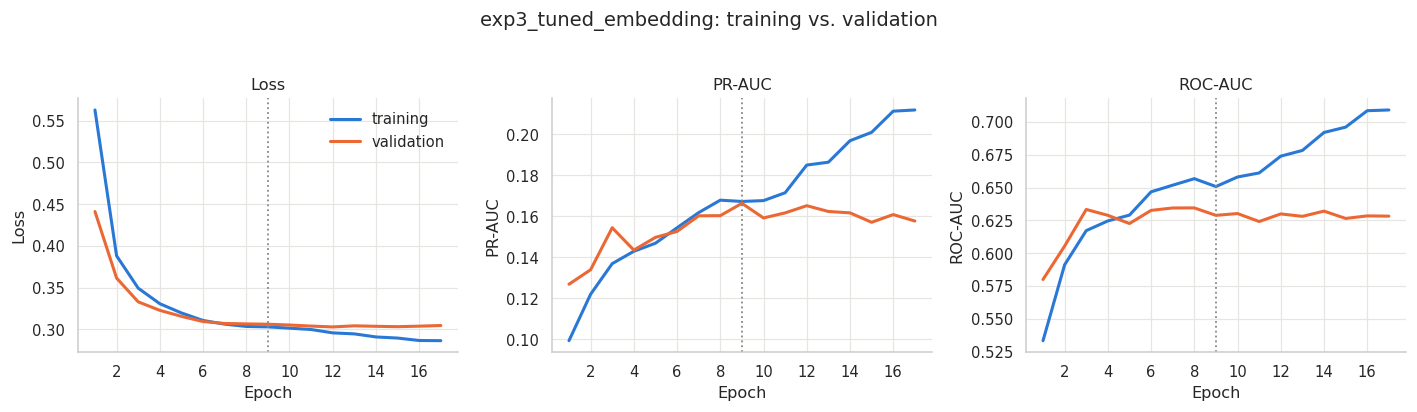

In [32]:
config.set_global_seed(SEED)
tuned_bs = best_hp.get("batch_size")
train_ds_e_tuned, _ = make_sets(Xtr_e, Xva_e, batch_size=tuned_bs)
m3t = hypermodel.build(best_hp)
m3t.summary()
run_experiment("exp3_tuned_embedding", m3t, train_ds_e_tuned, val_ds_e, Xva_e, "fig15_dl_exp3_tuned_history");

### 8.8 Experiment 4 – Class weights vs. focal loss on the tuned architecture
The tuned embedding model is retrained twice with two ways of handling imbalance:

* **4a – class weights**: binary cross-entropy where each positive counts `n / (2·n_pos)` times;
* **4b – focal loss** (`BinaryFocalCrossentropy`, γ = 2, α = 0.75 for the positive class): down-weights easy, confidently-correct examples so training focuses on hard ones.

Experiment 3-tuned (plain BCE) is the "no handling" reference.

Class weights: {0: 0.549, 1: 5.568}
exp4a_class_weights: 16 epochs, best val PR-AUC=0.1746 (epoch 8), 44s
saved figures/fig16_dl_exp4a_class_weights_history.png


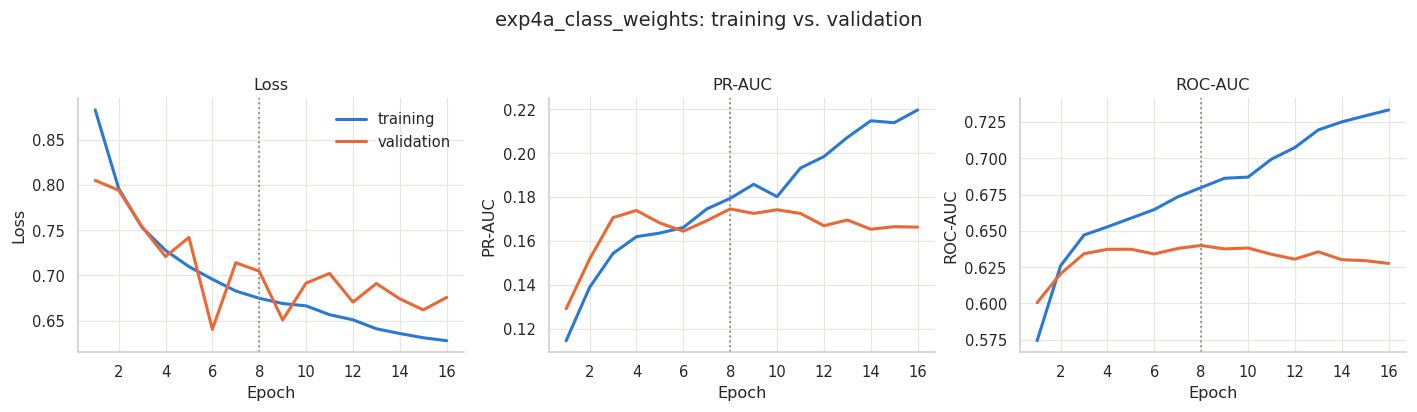

exp4b_focal_loss: 33 epochs, best val PR-AUC=0.1777 (epoch 25), 84s
saved figures/fig17_dl_exp4b_focal_loss_history.png


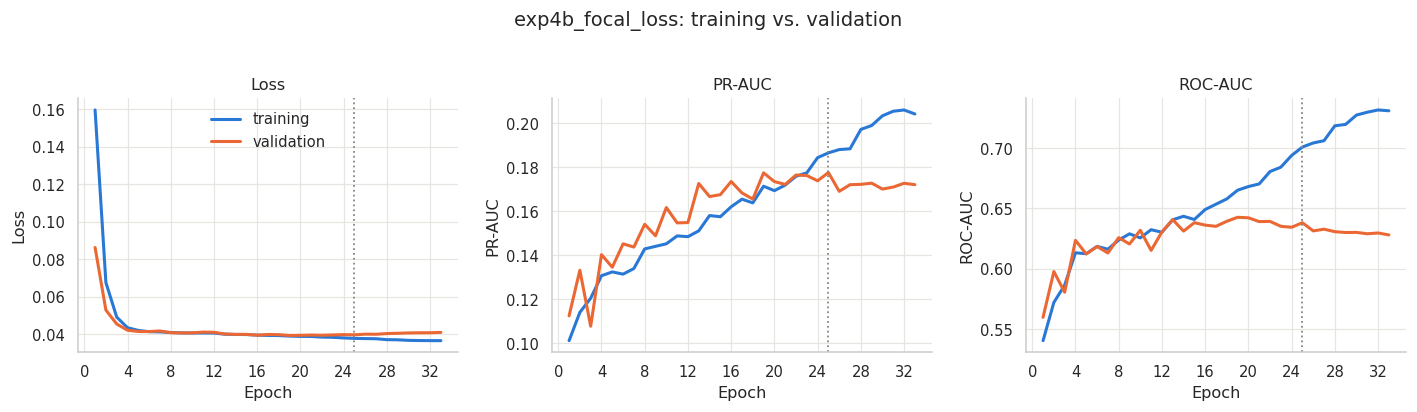

In [33]:
cw = dl_models.balanced_class_weight(y_train)
print("Class weights:", {k: round(v, 3) for k, v in cw.items()})

config.set_global_seed(SEED)
m4a = hypermodel.build(best_hp)
run_experiment("exp4a_class_weights", m4a, train_ds_e_tuned, val_ds_e, Xva_e,
               "fig16_dl_exp4a_class_weights_history", class_weight=cw)

config.set_global_seed(SEED)
m4b = hypermodel.build(best_hp)
dl_models.compile_model(m4b, best_hp.get("learning_rate"), loss="focal", alpha=0.75, gamma=2.0)
run_experiment("exp4b_focal_loss", m4b, train_ds_e_tuned, val_ds_e, Xva_e, "fig17_dl_exp4b_focal_loss_history");

### 8.9 Deep-learning summary (validation set)
Thresholds for each network are chosen on the validation set exactly as for the traditional models. The best network by validation PR-AUC is carried into the final comparison.

Best DL model on validation PR-AUC: exp4b_focal_loss
saved figures/fig18_validation_pr_auc_all_models.png


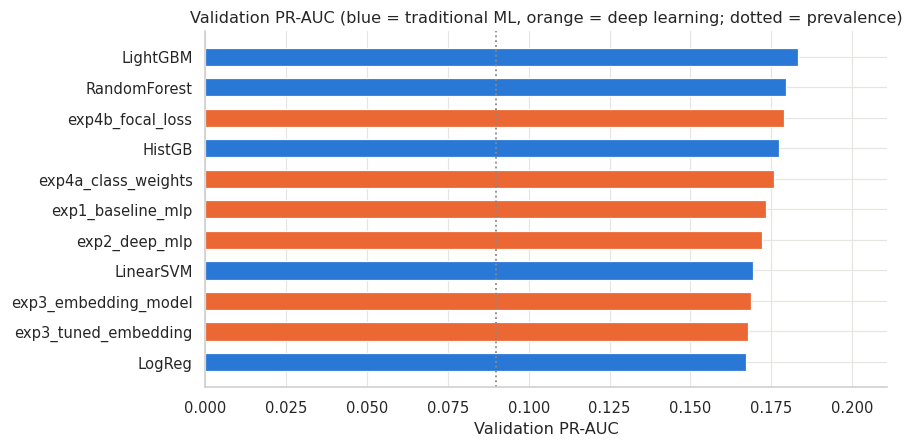

,model,family,epochs_trained,best_epoch,params,val_pr_auc,val_roc_auc,val_f1,f1_threshold,recall_threshold
5,exp4b_focal_loss,DL,33,25,25441,0.1789,0.6380,0.2465,0.4356,0.3666
4,exp4a_class_weights,DL,16,8,25441,0.1759,0.6399,0.2357,0.6046,0.4546
0,exp1_baseline_mlp,DL,24,16,10049,0.1735,0.6355,0.2394,0.1347,0.0678
1,exp2_deep_mlp,DL,20,12,82945,0.1720,0.6385,0.2397,0.1646,0.0742
2,exp3_embedding_model,DL,18,10,25104,0.1688,0.6335,0.2421,0.1583,0.0805
3,exp3_tuned_embedding,DL,17,9,25441,0.1677,0.6284,0.2360,0.1473,0.0894


In [34]:
dl_rows = []
for n, r in dl_runs.items():
    thresholds[n] = evaluation.choose_thresholds(y_val, r["val_proba"], TARGET_RECALL)
    met = evaluation.binary_metrics(y_val, r["val_proba"], thresholds[n]["f1_threshold"])
    dl_rows.append({"model": n, "family": "DL", "epochs_trained": len(r["hist"]),
                    "best_epoch": int(r["hist"]["val_pr_auc"].idxmax()) + 1, "params": r["model"].count_params(),
                    "val_pr_auc": met["pr_auc"], "val_roc_auc": met["roc_auc"], "val_f1": met["f1"],
                    "f1_threshold": thresholds[n]["f1_threshold"], "recall_threshold": thresholds[n]["recall_threshold"]})
val_dl = pd.DataFrame(dl_rows).sort_values("val_pr_auc", ascending=False)
best_dl_name = val_dl.iloc[0]["model"]
val_dl.to_csv(config.RESULTS_DIR / "dl_experiments_summary_val.csv", index=False)
print("Best DL model on validation PR-AUC:", best_dl_name)

val_all = pd.concat([val_ml, val_dl], ignore_index=True).sort_values("val_pr_auc", ascending=False)
val_all.to_csv(config.RESULTS_DIR / "validation_scores_all_models.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
d = val_all[val_all.model != "Dummy"].sort_values("val_pr_auc")
ax.barh(d["model"], d["val_pr_auc"], height=0.6,
        color=[plotting.PALETTE[1] if f == "DL" else plotting.PALETTE[0] for f in d["family"]])
ax.axvline(y_val.mean(), color=plotting.NEUTRAL, ls=":", lw=1.2)
ax.set_xlabel("Validation PR-AUC"); ax.set_title("Validation PR-AUC (blue = traditional ML, orange = deep learning; dotted = prevalence)")
ax.set_xlim(0, d["val_pr_auc"].max() * 1.15)
plotting.save(fig, "fig18_validation_pr_auc_all_models"); plt.show()
val_dl.round(4)

## 9. Final evaluation on the held-out test set
This is the **only** time the test set is used. Every model is evaluated at the threshold chosen on the validation set (max-F1), and 95 % confidence intervals for ROC-AUC and PR-AUC come from `N_BOOT` bootstrap resamples of the test rows. A second table reports each model at its recall-0.70 threshold.

In [35]:
X_test, y_test = features.as_model_frame(df_test, cols), df_test[config.TARGET].to_numpy()
Xte_d = dense_prep.transform(X_test).astype("float32")
Xte_e = emb_prep.transform(X_test)

test_proba = {n: m.predict_proba(X_test)[:, 1] for n, m in final_ml.items()}
for n, r in dl_runs.items():
    test_proba[n] = dl_models.predict_proba(r["model"], Xte_e if r["input"] == "embedding" else Xte_d)

f1_thr = {n: thresholds[n]["f1_threshold"] for n in test_proba}
test_table = evaluation.comparison_table(y_test, test_proba, f1_thr, n_boot=N_BOOT, seed=SEED)
test_table.to_csv(config.RESULTS_DIR / "test_comparison_full.csv", index=False)
evaluation.format_ci_table(test_table).to_csv(config.RESULTS_DIR / "test_comparison_report_table.csv", index=False)

rec_thr = {n: thresholds[n]["recall_threshold"] for n in test_proba}
test_table_rec = pd.DataFrame([{"model": n, **evaluation.binary_metrics(y_test, p, rec_thr[n])}
                               for n, p in test_proba.items()]).sort_values("pr_auc", ascending=False)
test_table_rec.to_csv(config.RESULTS_DIR / "test_metrics_at_recall70_threshold.csv", index=False)
evaluation.format_ci_table(test_table)

,model,threshold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc (95% CI),pr_auc (95% CI),brier
0,RandomForest,0.122,0.808,0.594,0.185,0.334,0.238,"0.650 [0.632, 0.670]","0.178 [0.160, 0.200]",0.079
1,LightGBM,0.133,0.828,0.589,0.198,0.298,0.238,"0.651 [0.634, 0.669]","0.178 [0.159, 0.200]",0.079
2,HistGB,0.128,0.819,0.589,0.189,0.309,0.234,"0.647 [0.630, 0.666]","0.177 [0.160, 0.200]",0.079
3,exp2_deep_mlp,0.165,0.804,0.589,0.178,0.326,0.230,"0.647 [0.630, 0.667]","0.173 [0.156, 0.194]",0.080
4,exp1_baseline_mlp,0.135,0.819,0.590,0.190,0.312,0.236,"0.648 [0.631, 0.666]","0.168 [0.152, 0.189]",0.079
5,LinearSVM,0.110,0.794,0.590,0.173,0.341,0.229,"0.644 [0.626, 0.664]","0.168 [0.151, 0.188]",0.080
6,exp3_embedding_model,0.158,0.796,0.587,0.171,0.332,0.226,"0.642 [0.624, 0.660]","0.167 [0.151, 0.188]",0.080
7,exp4b_focal_loss,0.436,0.832,0.579,0.192,0.269,0.224,"0.638 [0.620, 0.656]","0.165 [0.149, 0.185]",0.162
8,exp4a_class_weights,0.605,0.769,0.592,0.162,0.375,0.226,"0.639 [0.621, 0.658]","0.164 [0.148, 0.185]",0.239
9,LogReg,0.138,0.835,0.576,0.192,0.261,0.221,"0.643 [0.625, 0.662]","0.162 [0.147, 0.181]",0.080


> **What to look for:** whether the confidence intervals of the top models overlap (if they do, the ranking is not conclusive), how test recall compares with the validation recall the threshold was chosen for, and the gap to the Dummy model.

In [36]:
test_table_rec[["model", "threshold", "precision", "recall", "f1", "balanced_accuracy"]].round(3)

,model,threshold,precision,recall,f1,balanced_accuracy
2,RandomForest,0.080,0.121,0.727,0.208,0.603
4,LightGBM,0.071,0.120,0.741,0.206,0.602
3,HistGB,0.072,0.117,0.723,0.202,0.593
7,exp2_deep_mlp,0.074,0.118,0.733,0.203,0.596
6,exp1_baseline_mlp,0.068,0.117,0.723,0.201,0.592
5,LinearSVM,0.071,0.116,0.731,0.200,0.590
8,exp3_embedding_model,0.080,0.118,0.735,0.203,0.595
11,exp4b_focal_loss,0.367,0.116,0.712,0.199,0.588
10,exp4a_class_weights,0.455,0.117,0.729,0.202,0.594
1,LogReg,0.070,0.118,0.732,0.203,0.596


### 9.1 ROC and precision–recall curves
All tuned traditional models (solid lines) and the three best networks by validation PR-AUC (dashed) on one plot each; the Dummy model is represented by the chance line / prevalence line.

saved figures/fig19_roc_curves_test.png


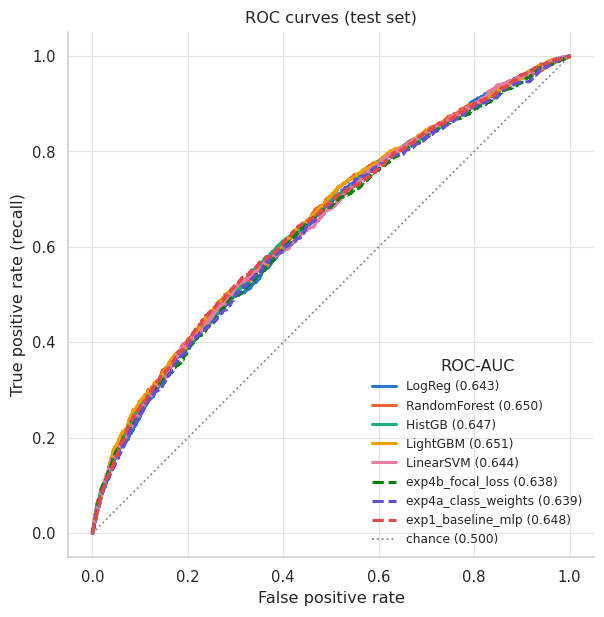

saved figures/fig20_pr_curves_test.png


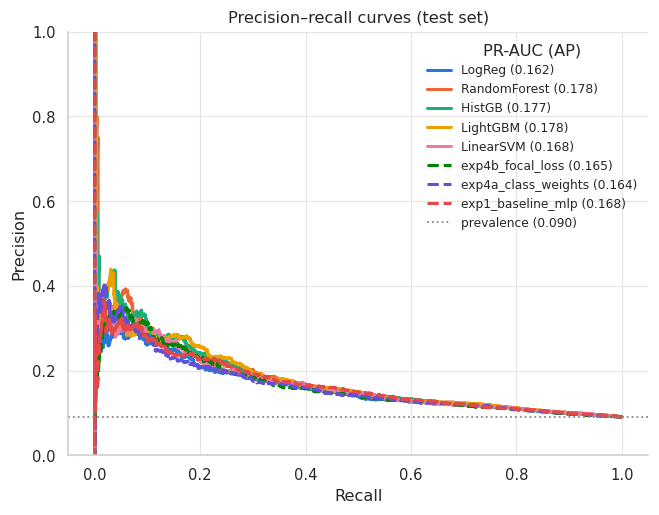

In [37]:
curve_models = [m for m in ML_MODELS if m != "Dummy"] + val_dl["model"].head(3).tolist()
curve_proba = {n: test_proba[n] for n in curve_models}
dl_names = set(dl_runs)
fig, ax = plt.subplots(figsize=(6.2, 6.2))
plotting.roc_overlay(y_test, curve_proba, "ROC curves (test set)", dl_names, ax)
plotting.save(fig, "fig19_roc_curves_test"); plt.show()
fig, ax = plt.subplots(figsize=(6.8, 5))
plotting.pr_overlay(y_test, curve_proba, "Precision–recall curves (test set)", dl_names, ax)
plotting.save(fig, "fig20_pr_curves_test"); plt.show()

### 9.2 Confusion matrices (best traditional and best deep-learning model)
At the validation max-F1 threshold; raw counts on the left, rows normalised by the true class on the right (the diagonal then shows specificity and recall).

saved figures/fig21_confusion_matrix_best_ml_test.png


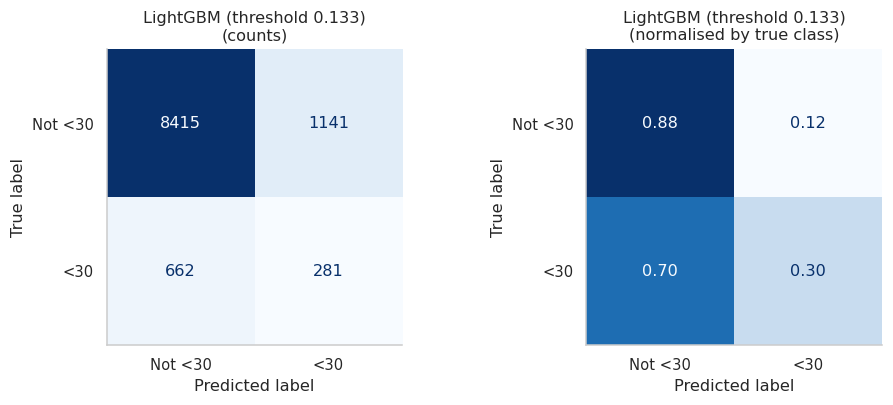

saved figures/fig22_confusion_matrix_best_dl_test.png


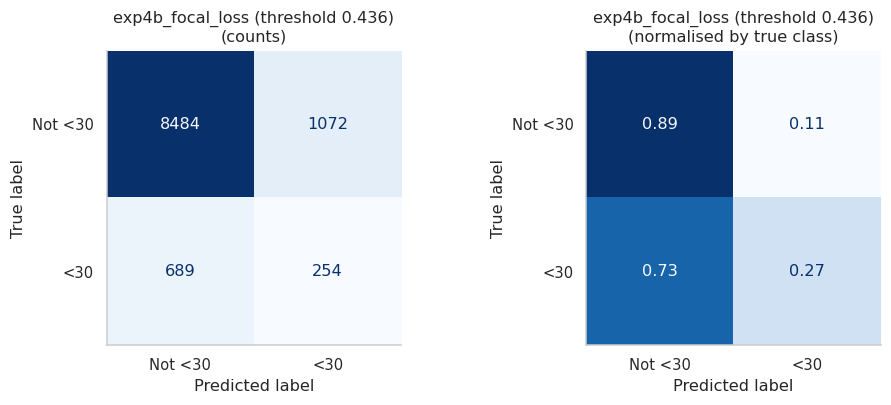

In [38]:
for name, fig_name in [(best_ml_name, "fig21_confusion_matrix_best_ml_test"),
                       (best_dl_name, "fig22_confusion_matrix_best_dl_test")]:
    pred = (test_proba[name] >= f1_thr[name]).astype(int)
    fig = plotting.confusion_pair(y_test, pred, f"{name} (threshold {f1_thr[name]:.3f})")
    plotting.save(fig, fig_name); plt.show()

### 9.3 Calibration and Brier score
A reliability plot compares the predicted probability with the observed `<30` rate in 10 equal-size bins. The Brier score is the mean squared error of the probabilities (lower is better; predicting the prevalence for everyone gives the Dummy's score). Models trained with class weights or resampling are expected to over-predict risk.

saved figures/fig23_calibration_test.png


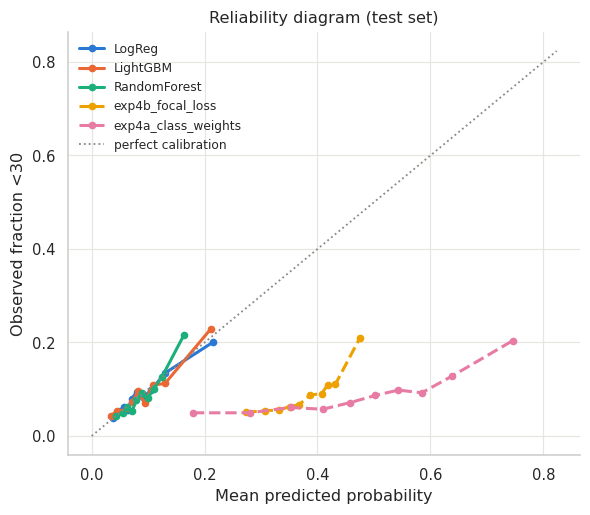

,model,brier
1,LightGBM,0.0789
2,HistGB,0.0790
4,exp1_baseline_mlp,0.0794
0,RandomForest,0.0795
5,LinearSVM,0.0795
9,LogReg,0.0797
3,exp2_deep_mlp,0.0801
6,exp3_embedding_model,0.0802
10,exp3_tuned_embedding,0.0804
11,Dummy,0.0818


In [39]:
calib_models = list(dict.fromkeys(["LogReg", best_ml_name, "RandomForest", best_dl_name, "exp4a_class_weights"]))
fig, ax = plt.subplots(figsize=(6, 5))
plotting.calibration_overlay(y_test, {n: test_proba[n] for n in calib_models}, "Reliability diagram (test set)",
                             dl_names=dl_names, ax=ax)
plotting.save(fig, "fig23_calibration_test"); plt.show()
brier = test_table[["model", "brier"]].sort_values("brier")
brier.to_csv(config.RESULTS_DIR / "test_brier_scores.csv", index=False)
brier.round(4)

## 10. Interpretability and error analysis

### 10.1 Permutation importance (best tree model)
Each original column is shuffled in turn and the drop in PR-AUC is measured, on the **validation** set (so the test set stays single-use). Because the whole pipeline is permuted at the raw-column level, a categorical feature counts as one feature regardless of how many one-hot columns it produces.

Best tree model: LightGBM
saved figures/fig24_permutation_importance_best_tree_val.png


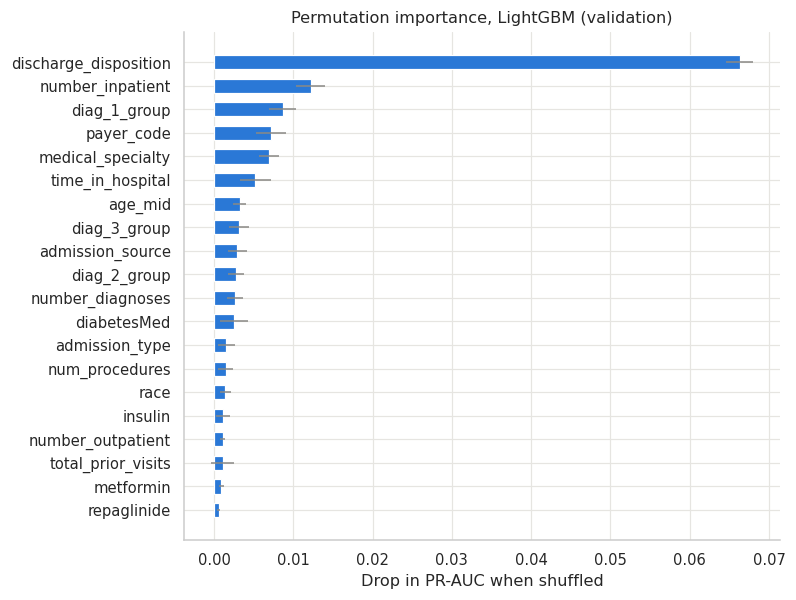

In [40]:
from sklearn.inspection import permutation_importance
tree_models = ["RandomForest", "HistGB", "LightGBM"]
best_tree = val_ml[val_ml.model.isin(tree_models)].iloc[0]["model"]
print("Best tree model:", best_tree)
pi = permutation_importance(final_ml[best_tree], X_val, y_val, scoring="average_precision",
                            n_repeats=PERM_REPEATS, random_state=SEED, n_jobs=N_JOBS)
pi_df = (pd.DataFrame({"feature": X_val.columns, "importance_mean": pi.importances_mean,
                       "importance_std": pi.importances_std})
         .sort_values("importance_mean", ascending=False).reset_index(drop=True))
pi_df.to_csv(config.RESULTS_DIR / "permutation_importance_val.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 6))
plotting.importance_bar(pi_df, f"Permutation importance, {best_tree} (validation)", top=20, ax=ax)
plotting.save(fig, "fig24_permutation_importance_best_tree_val"); plt.show()

### 10.2 SHAP values (best tree model)
`TreeExplainer` computes exact SHAP values for tree ensembles on the encoded features. The beeswarm plot shows each feature's effect on individual predictions (colour = feature value); the bar plot shows mean |SHAP|. Computed on a random sample of validation rows.

saved figures/fig25_shap_beeswarm_best_tree.png


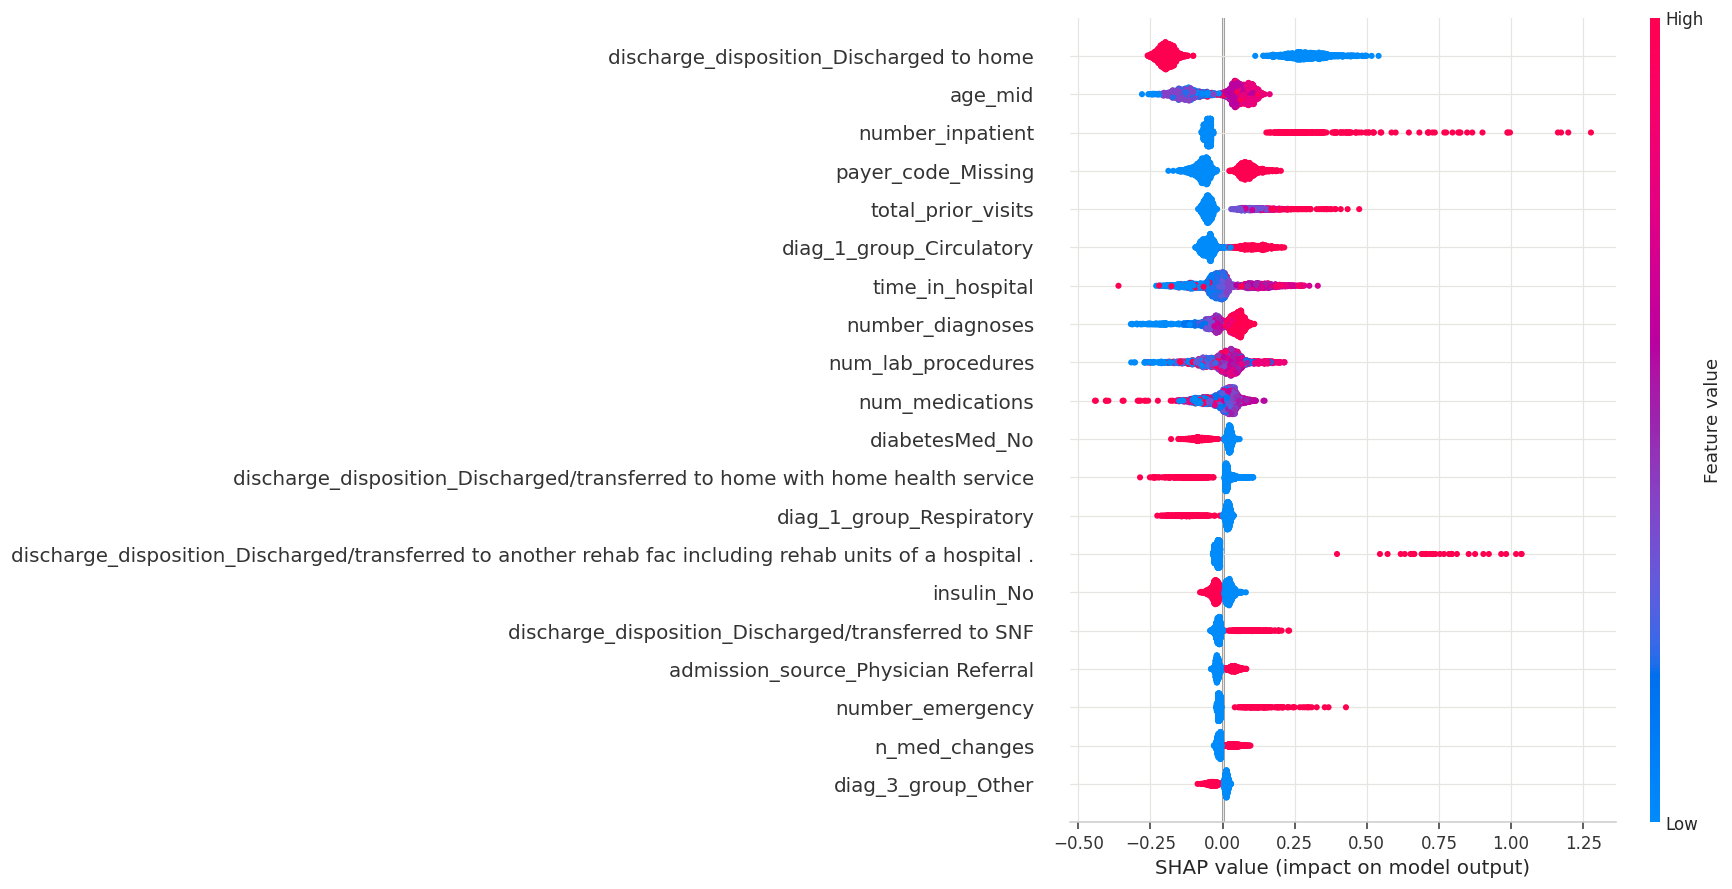

saved figures/fig26_shap_bar_best_tree.png


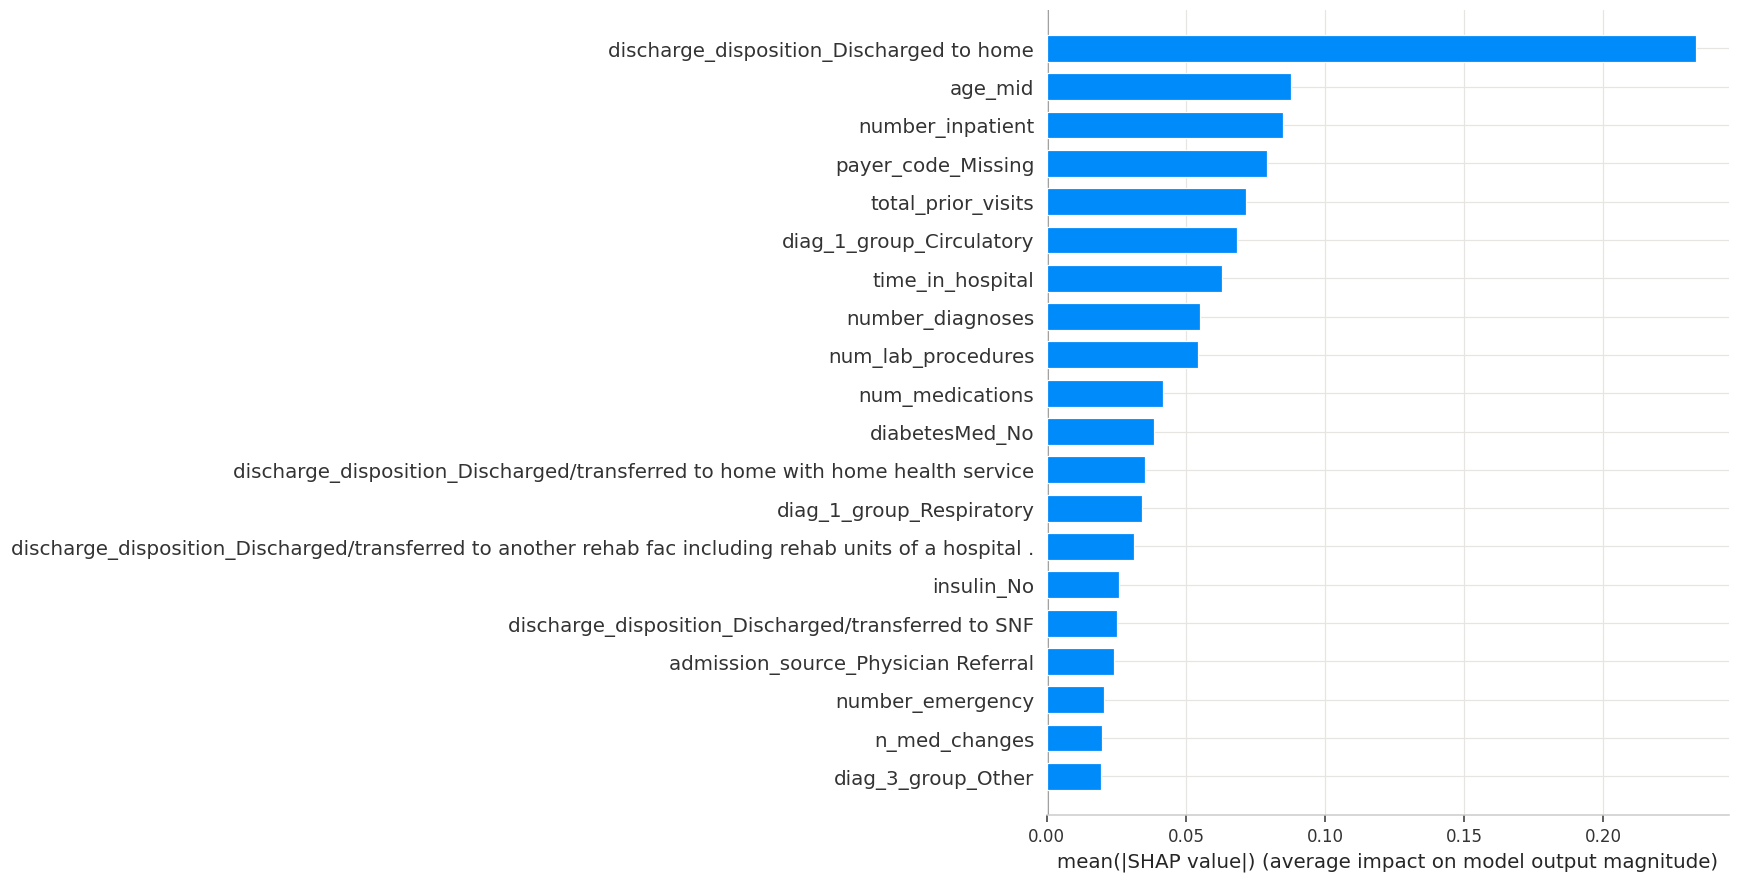

In [41]:
pipe = final_ml[best_tree]
enc_pipe = pipe[:-1]                       # prep + (sampler skipped at transform time) + encode
rng = np.random.default_rng(SEED)
sample = X_val.iloc[rng.choice(len(X_val), size=min(SHAP_ROWS, len(X_val)), replace=False)]
X_enc = pd.DataFrame(enc_pipe.transform(sample), columns=enc_pipe.named_steps["encode"].get_feature_names_out())
explainer = shap.TreeExplainer(pipe.named_steps["clf"])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    sv = explainer.shap_values(X_enc)
if isinstance(sv, list):
    sv = sv[1]
elif np.ndim(sv) == 3:
    sv = sv[:, :, 1]

warnings.filterwarnings("ignore", message=".*Tight layout not applied.*")
shap.summary_plot(sv, X_enc, max_display=20, show=False)
plotting.save(plt.gcf(), "fig25_shap_beeswarm_best_tree"); plt.show()
shap.summary_plot(sv, X_enc, plot_type="bar", max_display=20, show=False)
plotting.save(plt.gcf(), "fig26_shap_bar_best_tree"); plt.show()
shap_df = (pd.DataFrame({"feature": X_enc.columns, "mean_abs_shap": np.abs(sv).mean(axis=0)})
           .sort_values("mean_abs_shap", ascending=False))
shap_df.to_csv(config.RESULTS_DIR / "shap_mean_abs_best_tree.csv", index=False)

> **What to look for:** whether permutation importance and SHAP agree on the top features, and the direction of the effect in the beeswarm (e.g. high `number_inpatient` pushing predictions up).

### 10.3 Error analysis and fairness check
For the best model overall (by validation PR-AUC), test-set false negatives and false positives are broken down by age group, race, gender, admission type and number of prior inpatient visits. Each subgroup gets recall, precision, false-negative rate and false-positive rate. A subgroup is **flagged** if its recall is more than 0.10 below the overall recall and it has at least 30 positive cases (smaller groups are too noisy to judge).

Best model overall (validation PR-AUC): LightGBM
saved figures/fig27_subgroup_recall_test.png


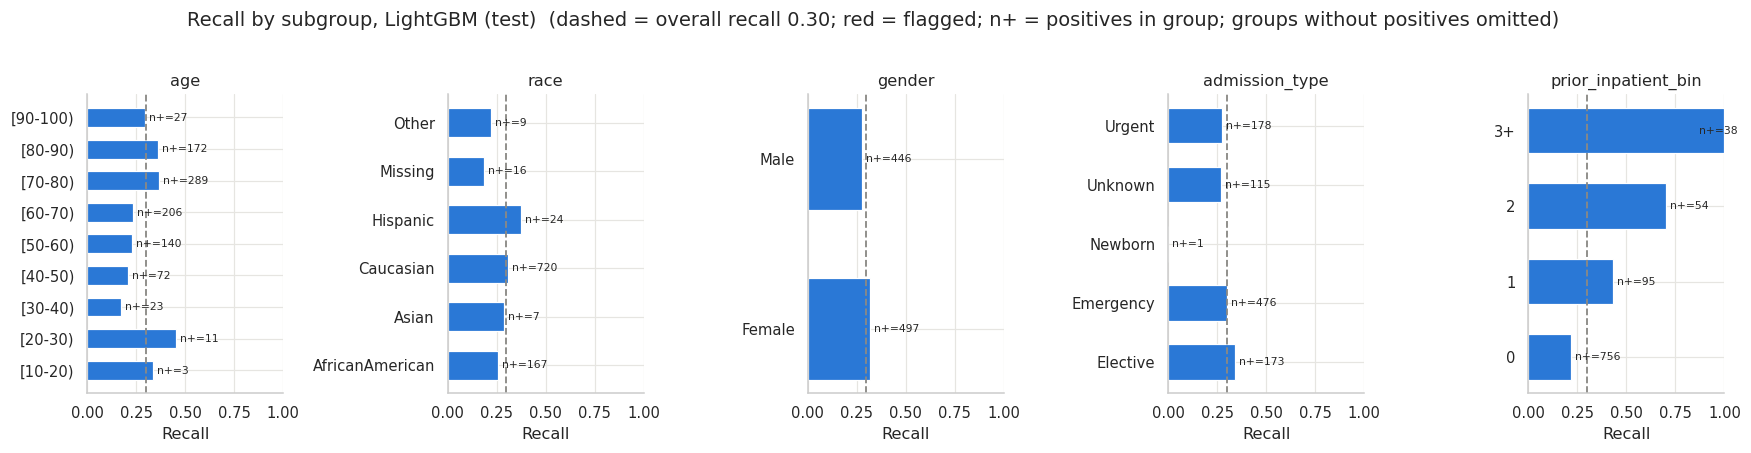

Overall recall: 0.298
Flagged subgroups:


,attribute,group,n,n_positive,recall,recall_gap_vs_overall,fpr


In [42]:
best_overall = val_all[val_all.model != "Dummy"].iloc[0]["model"]
print("Best model overall (validation PR-AUC):", best_overall)
pred_best = (test_proba[best_overall] >= f1_thr[best_overall]).astype(int)
err = evaluation.subgroup_error_analysis(df_test[config.SUBGROUP_COLS], y_test, pred_best, config.SUBGROUP_COLS,
                                         min_positives=30, recall_gap=0.10)
err.to_csv(config.RESULTS_DIR / "error_analysis_subgroups_test.csv", index=False)
fig = plotting.subgroup_recall_plot(err, f"Recall by subgroup, {best_overall} (test)")
plotting.save(fig, "fig27_subgroup_recall_test"); plt.show()
print(f"Overall recall: {err.attrs['overall_recall']:.3f}")
print("Flagged subgroups:")
err[err.flag_low_recall][["attribute", "group", "n", "n_positive", "recall", "recall_gap_vs_overall", "fpr"]].round(3)

In [43]:
err[["attribute", "group", "n", "n_positive", "TP", "FN", "FP", "TN", "recall", "precision", "fnr", "fpr",
     "share_of_all_FN", "share_of_all_FP"]].round(3)

,attribute,group,n,n_positive,TP,FN,FP,TN,recall,precision,fnr,fpr,share_of_all_FN,share_of_all_FP
0,age,[0-10),22,0,0,0,0,22,NaN,NaN,NaN,0.000,0.000,0.000
1,age,[10-20),91,3,1,2,3,85,0.333,0.250,0.667,0.034,0.003,0.003
2,age,[20-30),148,11,5,6,6,131,0.455,0.455,0.545,0.044,0.009,0.005
3,age,[30-40),387,23,4,19,21,343,0.174,0.160,0.826,0.058,0.029,0.018
4,age,[40-50),988,72,15,57,50,866,0.208,0.231,0.792,0.055,0.086,0.044
5,age,[50-60),1835,140,32,108,103,1592,0.229,0.237,0.771,0.061,0.163,0.090
6,age,[60-70),2311,206,48,158,244,1861,0.233,0.164,0.767,0.116,0.239,0.214
7,age,[70-80),2771,289,106,183,413,2069,0.367,0.204,0.633,0.166,0.276,0.362
8,age,[80-90),1693,172,62,110,274,1247,0.360,0.185,0.640,0.180,0.166,0.240
9,age,[90-100),253,27,8,19,27,199,0.296,0.229,0.704,0.119,0.029,0.024


> **What to look for:** subgroups that hold a large share of all false negatives, subgroups with small positive counts (wide uncertainty), and whether low recall in a group comes with a low false-positive rate (the model is simply more conservative there).

## 11. Secondary experiment: 3-class prediction (`<30` / `>30` / `NO`)
Same splits, same feature pipeline. Two models: multinomial Logistic Regression and LightGBM (with the hyperparameters tuned for the binary task), both with balanced class weights so the small `<30` class is not ignored. Evaluated with macro-F1 (each class counts equally), a per-class report and a confusion matrix on the test set.

saved figures/fig28_threeclass_confusion_matrix_test.png


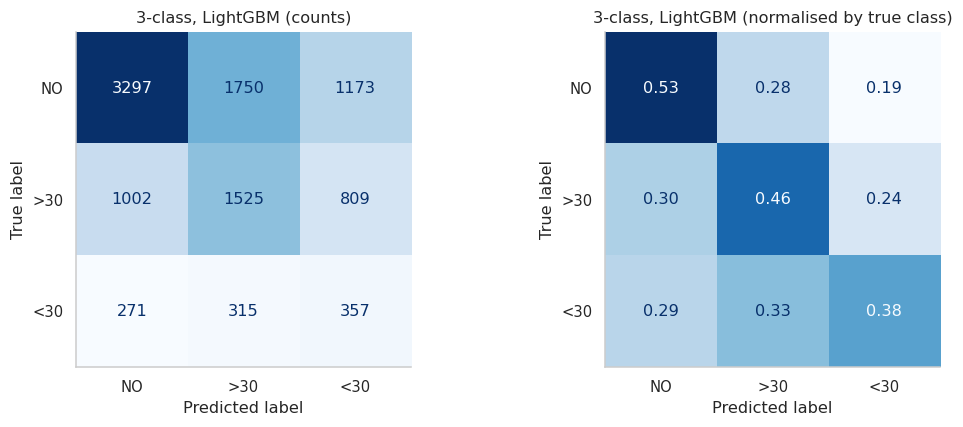

               model  val_macro_f1  test_macro_f1
LogReg (multinomial)        0.4035          0.408
            LightGBM        0.4247          0.423


,model,precision,recall,f1-score,support
NO,LogReg (multinomial),0.705,0.513,0.594,6220.000
>30,LogReg (multinomial),0.410,0.415,0.412,3336.000
<30,LogReg (multinomial),0.148,0.407,0.217,943.000
accuracy,LogReg (multinomial),0.473,0.473,0.473,0.473
macro avg,LogReg (multinomial),0.421,0.445,0.408,10499.000
weighted avg,LogReg (multinomial),0.561,0.473,0.503,10499.000
NO,LightGBM,0.721,0.530,0.611,6220.000
>30,LightGBM,0.425,0.457,0.440,3336.000
<30,LightGBM,0.153,0.379,0.218,943.000
accuracy,LightGBM,0.493,0.493,0.493,0.493


In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, confusion_matrix, ConfusionMatrixDisplay

y3_train, y3_val, y3_test = (d[config.TARGET_3CLASS].to_numpy() for d in (df_train, df_val, df_test))
lgbm_kw = ml_models.best_params_without_prefix(best_params["LightGBM"])
models_3 = {
    "LogReg (multinomial)": LogisticRegression(solver="lbfgs", max_iter=3000, class_weight="balanced"),
    "LightGBM": ml_models._lgbm()(**{**ml_models.make_estimator("LightGBM").get_params(), **lgbm_kw,
                                      "class_weight": "balanced", "objective": "multiclass"}),
}
rows3, reports3, preds3 = [], [], {}
for n, est in models_3.items():
    p3 = pipelines.build_model_pipeline(est, cols, "none", rare_min_freq=best_rare, seed=SEED).fit(X_train, y3_train)
    preds3[n] = p3.predict(X_test)
    rows3.append({"model": n, "val_macro_f1": f1_score(y3_val, p3.predict(X_val), average="macro"),
                  "test_macro_f1": f1_score(y3_test, preds3[n], average="macro")})
    rep = pd.DataFrame(classification_report(y3_test, preds3[n], target_names=config.CLASS_NAMES_3,
                                             output_dict=True)).T
    rep.insert(0, "model", n); reports3.append(rep)
three_df = pd.DataFrame(rows3)
three_df.to_csv(config.RESULTS_DIR / "threeclass_macro_f1.csv", index=False)
pd.concat(reports3).to_csv(config.RESULTS_DIR / "threeclass_classification_report_test.csv")

best3 = three_df.sort_values("val_macro_f1").iloc[-1]["model"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, norm, sub in zip(axes, [None, "true"], ["counts", "normalised by true class"]):
    ConfusionMatrixDisplay(confusion_matrix(y3_test, preds3[best3], normalize=norm),
                           display_labels=config.CLASS_NAMES_3).plot(ax=ax, cmap=plotting.SEQ_CMAP, colorbar=False,
                                                                     values_format=".2f" if norm else "d")
    ax.set_title(f"3-class, {best3} ({sub})"); ax.grid(False)
fig.tight_layout(); plotting.save(fig, "fig28_threeclass_confusion_matrix_test"); plt.show()
print(three_df.round(4).to_string(index=False))
pd.concat(reports3).round(3)

> **What to look for:** the per-class recall of `<30` compared with the binary model, and which classes are confused with each other most.

## 12. Saving models, preprocessors and thresholds
* `best_traditional_model.joblib`: the complete fitted imblearn Pipeline (preprocessing + model), so it accepts the raw feature DataFrame;
* `best_dl_model.keras` (native Keras format) plus a TensorFlow SavedModel export in `best_dl_model_savedmodel/`;
* the fitted DL preprocessors (`dl_dense_preprocessor.joblib`, `dl_embedding_preprocessor.joblib`);
* `feature_columns.json`: the column lists the models expect;
* `thresholds.json`: the validation-chosen thresholds for every model.

In [45]:
M = config.MODELS_DIR
joblib.dump(final_ml[best_ml_name], M / "best_traditional_model.joblib", compress=3)
best_dl_model = dl_runs[best_dl_name]["model"]
best_dl_model.save(M / "best_dl_model.keras")
best_dl_model.export(str(M / "best_dl_model_savedmodel"))
joblib.dump(dense_prep, M / "dl_dense_preprocessor.joblib")
joblib.dump(emb_prep, M / "dl_embedding_preprocessor.joblib")

(M / "feature_columns.json").write_text(json.dumps({**cols, "kept_drug_columns": kept_drugs,
                                                     "dropped_columns": dropped_cols}, indent=2))
(M / "thresholds.json").write_text(json.dumps({
    "best_traditional_model": {"name": best_ml_name, **thresholds[best_ml_name]},
    "best_dl_model": {"name": best_dl_name, "input": dl_runs[best_dl_name]["input"], **thresholds[best_dl_name]},
    "all_models": thresholds}, indent=2))
for p in sorted(M.glob("*")):
    size = sum(f.stat().st_size for f in p.rglob("*")) if p.is_dir() else p.stat().st_size
    print(f"{p.name:40s} {size / 1e6:8.2f} MB")

Saved artifact at '/content/intro_to_ml_summative/models/best_dl_model_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): Dict[['diag_1_group', TensorSpec(shape=(None,), dtype=tf.int32, name='diag_1_group')], ['diag_2_group', TensorSpec(shape=(None,), dtype=tf.int32, name='diag_2_group')], ['diag_3_group', TensorSpec(shape=(None,), dtype=tf.int32, name='diag_3_group')], ['medical_specialty', TensorSpec(shape=(None,), dtype=tf.int32, name='medical_specialty')], ['admission_source', TensorSpec(shape=(None,), dtype=tf.int32, name='admission_source')], ['discharge_disposition', TensorSpec(shape=(None,), dtype=tf.int32, name='discharge_disposition')], ['admission_type', TensorSpec(shape=(None,), dtype=tf.int32, name='admission_type')], ['payer_code', TensorSpec(shape=(None,), dtype=tf.int32, name='payer_code')], ['numeric', TensorSpec(shape=(None, 75), dtype=tf.float32, name='numeric')]]
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.flo

## 13. Inference example
This cell starts from **raw rows** of `diabetic_data.csv` (a few test-set encounters, looked up by `encounter_id`), runs them through the same cleaning and feature-engineering functions, loads the saved models from disk and predicts. This is the workflow for scoring a new patient.

In [46]:
loaded_ml = joblib.load(M / "best_traditional_model.joblib")
loaded_dl = keras.models.load_model(M / "best_dl_model.keras")
thr = json.loads((M / "thresholds.json").read_text())
feat_cols = json.loads((M / "feature_columns.json").read_text())
dl_prep = joblib.load(M / ("dl_embedding_preprocessor.joblib" if thr["best_dl_model"]["input"] == "embedding"
                           else "dl_dense_preprocessor.joblib"))

new_raw, _ = data.load_raw("local", config.RAW_DIR)
new_raw = new_raw[new_raw.encounter_id.isin(df_test.encounter_id.head(5))]
new = features.add_engineered_features(data.clean(data.replace_question_marks(new_raw)), data.load_id_mappings(ids_path))
X_new = features.as_model_frame(new, feat_cols)

p_ml = loaded_ml.predict_proba(X_new)[:, 1]
X_new_dl = dl_prep.transform(X_new)
p_dl = dl_models.predict_proba(loaded_dl, X_new_dl if isinstance(X_new_dl, dict) else X_new_dl.astype("float32"))
pd.DataFrame({
    "encounter_id": new.encounter_id.values, "true_label": new[config.TARGET_RAW].values,
    f"p_<30 ({thr['best_traditional_model']['name']})": p_ml.round(3),
    "ML_flag": (p_ml >= thr["best_traditional_model"]["f1_threshold"]).astype(int),
    f"p_<30 ({thr['best_dl_model']['name']})": p_dl.round(3),
    "DL_flag": (p_dl >= thr["best_dl_model"]["f1_threshold"]).astype(int),
})

,encounter_id,true_label,p_<30 (LightGBM),ML_flag,p_<30 (exp4b_focal_loss),DL_flag
0,64410,NO,0.090,0,0.419,0
1,150048,NO,0.055,0,0.300,0
2,550098,<30,0.083,0,0.436,1
3,685086,NO,0.160,1,0.440,1
4,881016,>30,0.065,0,0.392,0


## 14. Output index
Lists every figure and table produced by this run.

In [47]:
print("Figures:"); [print("  ", p.name) for p in sorted(config.FIG_DIR.glob("*.png"))]
print("Tables:");  [print("  ", p.name) for p in sorted(config.RESULTS_DIR.glob("*.csv"))]
print(f"FAST_MODE = {FAST_MODE}");

Figures:
   fig01_target_distribution_raw.png
   fig02_missingness.png
   fig03_encounters_per_patient.png
   fig04_numeric_features_vs_target_train.png
   fig05_categorical_features_vs_target_train.png
   fig06_imbalance_strategies_cv.png
   fig07_feature_ablation_cv.png
   fig08_ml_tuning_all_configs_cv.png
   fig09_threshold_selection_best_ml_val.png
   fig10_learning_curves_top2_ml.png
   fig11_patient_leakage_experiment.png
   fig12_dl_exp1_baseline_mlp_history.png
   fig13_dl_exp2_deep_mlp_history.png
   fig14_dl_exp3_embedding_history.png
   fig15_dl_exp3_tuned_history.png
   fig16_dl_exp4a_class_weights_history.png
   fig17_dl_exp4b_focal_loss_history.png
   fig18_validation_pr_auc_all_models.png
   fig19_roc_curves_test.png
   fig20_pr_curves_test.png
   fig21_confusion_matrix_best_ml_test.png
   fig22_confusion_matrix_best_dl_test.png
   fig23_calibration_test.png
   fig24_permutation_importance_best_tree_val.png
   fig25_shap_beeswarm_best_tree.png
   fig26_shap_bar_best_tre